# Submission versi 4 — EDA sampai submission.csv

    Notebook ini mereview pipeline yang menghasilkan **submission_v4.csv**.
    Skor public historis: **belum tercatat**.
    Skor tersebut milik file historis, bukan jaminan untuk eksperimen yang Anda ubah.

    **Urutan membaca:** persiapan → EDA → pembentukan fitur → preprocessing →
    validasi dan pemilihan model → prediksi test → pemeriksaan dan ekspor CSV.

    Jalankan **Kernel → Restart & Run All**. Model/fitur cache dipakai jika tersedia;
    `.fit()` otomatis berjalan jika model belum tersedia. Untuk melatih ulang seluruhnya,
    ubah flag pada sel persiapan. Pencarian parameter yang mahal bersifat opsional.

    Output setiap notebook disimpan pada direktori versinya sendiri dengan nama
    **submission.csv**, agar hasil beberapa versi bisa dibandingkan.
    Notebook tidak mengirim submission ke Kaggle.

    Instal dependensi dari direktori proyek: `python -m pip install -r requirements-optimization.txt -r requirements-notebook.txt`.
    Data mentah harus tersedia di `data/raw/`; unduh sekali dengan `python scripts/download_data.py`.
    Kredensial tidak perlu ditulis dalam notebook.

## 1. Persiapan lingkungan

Semua jalur relatif terhadap proyek. Cache mempercepat review; kode training tetap ada di sel notebook.

In [1]:
RUN_NAME = "05_v4"
CANONICAL_FILE = "submission_v4.csv"
PUBLIC_SCORE = None

from pathlib import Path
import gc, hashlib, itertools, json, os, time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import ks_2samp
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.metrics import average_precision_score, log_loss, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, SplineTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression
from threadpoolctl import threadpool_limits
from xgboost import XGBClassifier
from xgboost.callback import EarlyStopping
from lightgbm import LGBMClassifier, early_stopping, log_evaluation
from catboost import CatBoostClassifier

# Ubah empat pilihan ini jika ingin membangun dan melatih semuanya ulang.
FORCE_REBUILD_FEATURES = False
FORCE_RETRAIN_MODELS = False
FORCE_RECOMPUTE_VALIDATION = False
RUN_OPTIONAL_SEARCH = False

ROOT = Path(os.environ.get("LOGIKA_PROJECT_DIR", Path.cwd())).resolve()
if not (ROOT / "scripts/analyze.py").exists():
    ROOT = next(p for p in ROOT.parents if (p / "scripts/analyze.py").exists())
RAW = ROOT / "data/raw"
PROCESSED = Path(os.environ.get("LOGIKA_FEATURE_DIR", ROOT / "data/processed"))
OUT = ROOT / "artifacts/notebook_runs" / RUN_NAME
TABLES = OUT / "tables"
for folder in [PROCESSED, OUT, TABLES, OUT / "models"]:
    folder.mkdir(parents=True, exist_ok=True)
KEY, TARGET = "customer_id", "target"
EXCLUDED = {
    "application_id",
    "customer_id",
    "application_datetime",
    "decision_datetime",
    "target",
    "split",
}
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 20)
print("Proyek:", ROOT)
print("Output notebook:", OUT / "submission.csv")

Proyek: /home/taqiyudinmiftah/Logika
Output notebook: /home/taqiyudinmiftah/Logika/artifacts/notebook_runs/05_v4/submission.csv


## 2. Memahami target dan data

`target=1` berarti pinjaman mencapai DPD ≥90 dalam 12 bulan setelah origination. Test tidak memiliki target. Ada satu aplikasi terpilih per customer, sehingga agregasi seluruh tabel riwayat memakai customer_id. Perbedaan rasio target menurut kelompok bersifat deskriptif dan bukan kesimpulan sebab-akibat.

,dataset,baris,kolom,target_positif,rasio_positif
0,train,70000,10,9507.0,0.135814
1,test,30000,9,NaN,NaN


,tipe,missing
application_id,object,0
customer_id,object,0
application_datetime,datetime64[ns],0
decision_datetime,datetime64[ns],0
loan_amount,int64,0
term_months,int64,0
annual_interest_rate,float64,0
proposed_monthly_installment,int64,0
loan_purpose,object,0
target,int64,0


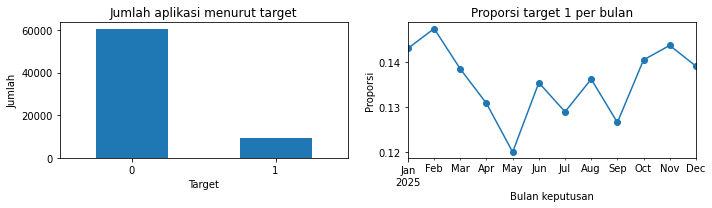

,aplikasi,rasio_target_1
employment_type,,
salaried,33473,0.132405
self_employed,20987,0.137943
variable_income,15540,0.140283


Urutan sample sama dengan test: False


In [2]:
train_raw = pd.read_csv(
    RAW / "train_applications.csv", parse_dates=["application_datetime", "decision_datetime"]
)
test_raw = pd.read_csv(
    RAW / "test_applications.csv", parse_dates=["application_datetime", "decision_datetime"]
)
sample = pd.read_csv(RAW / "sample_submission.csv")
profiles_eda = pd.read_csv(RAW / "customer_profiles.csv")
assert train_raw.application_id.is_unique and test_raw.application_id.is_unique
assert set(train_raw.customer_id).isdisjoint(test_raw.customer_id)
assert set(test_raw.application_id) == set(sample.application_id)
assert train_raw.target.isin([0, 1]).all()
display(
    pd.DataFrame(
        [
            {
                "dataset": "train",
                "baris": len(train_raw),
                "kolom": len(train_raw.columns),
                "target_positif": int(train_raw.target.sum()),
                "rasio_positif": train_raw.target.mean(),
            },
            {
                "dataset": "test",
                "baris": len(test_raw),
                "kolom": len(test_raw.columns),
                "target_positif": np.nan,
                "rasio_positif": np.nan,
            },
        ]
    )
)
display(
    pd.DataFrame({"tipe": train_raw.dtypes.astype(str), "missing": train_raw.isna().sum()})
)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
train_raw.target.value_counts().sort_index().plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Jumlah aplikasi menurut target", xlabel="Target", ylabel="Jumlah")
monthly = train_raw.groupby(train_raw.decision_datetime.dt.to_period("M")).target.agg(
    ["mean", "size"]
)
monthly["mean"].plot(marker="o", ax=axes[1])
axes[1].set(title="Proporsi target 1 per bulan", xlabel="Bulan keputusan", ylabel="Proporsi")
plt.tight_layout()
plt.show()
profile = train_raw[["customer_id", "target"]].merge(
    profiles_eda, on="customer_id", validate="one_to_one"
)
display(profile.groupby("employment_type").target.agg(aplikasi="size", rasio_target_1="mean"))
print("Urutan sample sama dengan test:", sample.application_id.equals(test_raw.application_id))
del profile, profiles_eda

## 3. Metrik KS dan risiko kebocoran

KS adalah maksimum selisih dua distribusi kumulatif skor. Dalam ROC, nilainya sama dengan maksimum |TPR−FPR|. KS mengukur pemisahan; submission tetap berupa probabilitas kontinu. Model validasi tidak boleh dilatih pada baris validasi. Informasi riwayat harus tersedia sebelum decision_datetime, dan opaque ID tidak menjadi fitur.

In [3]:
def ks(y, probability):
    fpr, tpr, _ = roc_curve(y, probability, drop_intermediate=False)
    return float(np.max(np.abs(tpr - fpr)))


def lgb_ks(y, probability):
    return "ks", ks(y, probability), True


def metrics(y, probability):
    return {
        "ks": ks(y, probability),
        "roc_auc": roc_auc_score(y, probability),
        "average_precision": average_precision_score(y, probability),
        "log_loss": log_loss(y, probability),
    }

## 4. Fitur dasar: alat bantu dan pengaturan cache

Sel fitur berikut berisi kode agregasi yang digunakan pada eksperimen asli. Jika parquet tersedia, blok `if NEED_...` dilewati. Aktifkan `FORCE_REBUILD_FEATURES` untuk membaca ulang seluruh riwayat. Kode tetap terlihat dan dapat diedit langsung di notebook.

In [4]:
def safe_ratio(a, b):
    return a / b.where(b > 0)


def read(name, dates=()):
    return pd.read_csv(RAW / f"{name}.csv", parse_dates=list(dates))


def ratio(a, b):
    return a / b.where(b > 0)


NEED_BASE = FORCE_REBUILD_FEATURES or not (PROCESSED / "application_features.parquet").exists()
NEED_BASE = NEED_BASE or not (PROCESSED / "bureau_latest.parquet").exists()
print("Bangun fitur dasar:", NEED_BASE)

Bangun fitur dasar: False


### Persiapan audit

Setiap aplikasi memiliki satu customer. Audit mencatat duplikasi, relasi tabel, missing value, dan ketersediaan riwayat.

In [5]:
if NEED_BASE:
    for folder in [PROCESSED, TABLES, OUT / "figures"]:
        folder.mkdir(parents=True, exist_ok=True)
    train = read("train_applications", ["application_datetime", "decision_datetime"])
    test = read("test_applications", ["application_datetime", "decision_datetime"])
    train["split"] = "train"
    test["split"] = "test"
    base = pd.concat([train, test], ignore_index=True)
    assert base.application_id.is_unique and base.customer_id.is_unique
    cutoff = base[[KEY, "decision_datetime"]].rename(columns={"decision_datetime": "cutoff"})
    inventory, missing, audits, coverage = [], [], {}, []

    def inspect(df, name, primary):
        inventory.append(
            {
                "table": name,
                "rows": len(df),
                "columns": len(df.columns),
                "customers": df[KEY].nunique() if KEY in df else np.nan,
                "size_mb": (RAW / f"{name}.csv").stat().st_size / 1e6,
            }
        )
        for col in df:
            missing.append(
                {
                    "table": name,
                    "column": col,
                    "dtype": str(df[col].dtype),
                    "missing": int(df[col].isna().sum()),
                    "missing_pct": 100 * df[col].isna().mean(),
                    "unique_values": df[col].nunique(),
                }
            )
        audits[name] = {
            "duplicate_rows": int(df.duplicated().sum()),
            "duplicate_primary_keys": int(df.duplicated(primary).sum()),
        }
        if KEY in df:
            ids = set(df[KEY])
            audits[name]["orphan_customers"] = len(ids - set(base[KEY]))
            for part in ["train", "test"]:
                subset = base[base.split.eq(part)]
                coverage.append(
                    {
                        "table": name,
                        "split": part,
                        "covered_customers": int(subset[KEY].isin(ids).sum()),
                        "coverage_pct": 100 * subset[KEY].isin(ids).mean(),
                    }
                )
        print(f"Audited {name}: {len(df):,} rows", flush=True)

    def at_cutoff(df, name, cols):
        df = df.merge(cutoff, on=KEY, how="left", validate="many_to_one")
        assert df.cutoff.notna().all()
        for col in cols:
            audits[name][f"{col}_at_or_after_cutoff"] = int(df[col].ge(df.cutoff).sum())
        return df

    def attach(features):
        global base
        assert features.index.is_unique
        base = base.merge(
            features, left_on=KEY, right_index=True, how="left", validate="one_to_one"
        )
        assert len(base) == len(train) + len(test)

### Profil dan rasio kemampuan bayar

Gabungkan profil satu-ke-satu; rasio cicilan/pendapatan lebih mudah dipelajari model daripada dua jumlah rupiah terpisah.

In [6]:
if NEED_BASE:
    inspect(train.drop(columns="split"), "train_applications", "application_id")
    inspect(test.drop(columns="split"), "test_applications", "application_id")
    submission = read("sample_submission")
    inspect(submission, "sample_submission", "application_id")
    audits["submission"] = {
        "same_id_set_as_test": set(submission.application_id) == set(test.application_id),
        "same_row_order_as_test": submission.application_id.equals(test.application_id),
        "target_column": "default_probability",
    }
    profiles = read("customer_profiles")
    inspect(profiles, "customer_profiles", KEY)
    base = base.merge(profiles, on=KEY, how="left", validate="one_to_one")
    assert base.age.notna().all()
    base["installment_income_ratio"] = safe_ratio(
        base.proposed_monthly_installment, base.declared_monthly_income
    )
    base["loan_income_ratio"] = safe_ratio(base.loan_amount, base.declared_monthly_income)
    base["income_per_dependent"] = base.declared_monthly_income / (1 + base.dependents)
    base["decision_delay_hours"] = (
        base.decision_datetime - base.application_datetime
    ).dt.total_seconds() / 3600
    rate = base.annual_interest_rate / 12
    theoretical = (
        base.loan_amount
        * rate
        * (1 + rate) ** base.term_months
        / ((1 + rate) ** base.term_months - 1)
    )
    audits["applications"] = {
        "train_test_customer_overlap": len(set(train[KEY]) & set(test[KEY])),
        "train_test_application_overlap": len(
            set(train.application_id) & set(test.application_id)
        ),
        "decision_before_application": int(
            (base.decision_datetime < base.application_datetime).sum()
        ),
        "nonpositive_income": int(base.declared_monthly_income.le(0).sum()),
        "installment_formula_max_rounding_difference_idr": float(
            abs(base.proposed_monthly_installment - theoretical.round()).max()
        ),
        "term_months_values": sorted(base.term_months.unique().tolist()),
    }
    del profiles

### Riwayat aplikasi

Ambil keputusan sebelum cutoff. Hitung persetujuan, penolakan, dan jarak waktu aplikasi terakhir.

In [7]:
if NEED_BASE:
    name = "previous_applications"
    prev = read(name, ["application_datetime", "decision_datetime"])
    inspect(prev, name, "application_id")
    historical_ids = set(prev.application_id)
    approved_loans = set(prev.loan_id.dropna())
    loan_customers = prev.loc[prev.loan_id.notna(), ["loan_id", KEY]].set_index("loan_id")[KEY]
    audits[name]["overlap_with_selected_application_ids"] = len(
        historical_ids & set(base.application_id)
    )
    prev = at_cutoff(prev, name, ["application_datetime", "decision_datetime"])
    prev = prev[prev.decision_datetime.lt(prev.cutoff)].copy()
    for status in ["approved", "rejected", "cancelled"]:
        prev[f"is_{status}"] = prev.decision.eq(status).astype(int)
    prev["recency_days"] = (prev.cutoff - prev.decision_datetime).dt.total_seconds() / 86400
    features = prev.groupby(KEY).agg(
        previous_count=("application_id", "size"),
        previous_approved_count=("is_approved", "sum"),
        previous_rejection_rate=("is_rejected", "mean"),
        previous_cancel_rate=("is_cancelled", "mean"),
        previous_requested_mean=("requested_amount", "mean"),
        previous_approved_amount_mean=("approved_amount", "mean"),
        previous_installment_mean=("scheduled_monthly_installment", "mean"),
        previous_last_recency_days=("recency_days", "min"),
    )
    for days in [90, 180]:
        features[f"previous_count_{days}d"] = (
            prev[prev.recency_days.le(days)]
            .groupby(KEY)
            .size()
            .reindex(features.index, fill_value=0)
        )
    attach(features)
    base["has_previous"] = base.previous_count.notna().astype(int)
    del prev, features
    gc.collect()

### Riwayat pembayaran

DPD adalah days past due. Snapshot pembayaran harus diketahui sebelum keputusan, termasuk waktu pembayaran terakhir.

In [8]:
if NEED_BASE:
    name = "repayment_history"
    repay = read(name, ["due_date", "last_payment_datetime"])
    inspect(repay, name, "installment_id")
    audits[name]["loans_not_in_approved_history"] = len(set(repay.loan_id) - approved_loans)
    audits[name]["loan_customer_mismatches"] = int(
        repay.loan_id.map(loan_customers).ne(repay[KEY]).sum()
    )
    audits[name]["amount_paid_above_due"] = int(repay.amount_paid.gt(repay.amount_due).sum())
    audits[name]["max_dpd_below_current_dpd"] = int(
        repay.max_days_past_due.lt(repay.days_past_due).sum()
    )
    repay = at_cutoff(repay, name, ["due_date", "last_payment_datetime"])
    repay = repay[repay.due_date.lt(repay.cutoff)].copy()
    # Snapshot amounts/DPD are already measured before the selected decision.
    # Any future observed payment would invalidate this snapshot; do not silently use it.
    assert (
        repay.last_payment_datetime.dropna()
        .lt(repay.loc[repay.last_payment_datetime.notna(), "cutoff"])
        .all()
    )
    repay["unpaid_amount"] = (repay.amount_due - repay.amount_paid).clip(lower=0)
    for threshold in [1, 30, 90]:
        repay[f"ever_dpd_{threshold}"] = repay.max_days_past_due.ge(threshold).astype(int)
    repay["recency_days"] = (repay.cutoff - repay.due_date).dt.total_seconds() / 86400
    features = repay.groupby(KEY).agg(
        repayment_installment_count=("installment_id", "size"),
        repayment_loan_count=("loan_id", "nunique"),
        repayment_amount_due=("amount_due", "sum"),
        repayment_amount_paid=("amount_paid", "sum"),
        repayment_unpaid_amount=("unpaid_amount", "sum"),
        repayment_current_dpd_max=("days_past_due", "max"),
        repayment_historical_dpd_max=("max_days_past_due", "max"),
        repayment_historical_dpd_mean=("max_days_past_due", "mean"),
        repayment_late_share=("ever_dpd_1", "mean"),
        repayment_dpd30_share=("ever_dpd_30", "mean"),
        repayment_dpd90_share=("ever_dpd_90", "mean"),
    )
    features["repayment_paid_ratio"] = safe_ratio(
        features.repayment_amount_paid, features.repayment_amount_due
    )
    recent = (
        repay[repay.recency_days.le(180)]
        .groupby(KEY)
        .agg(
            repayment_dpd_mean_180d=("max_days_past_due", "mean"),
            repayment_unpaid_180d=("unpaid_amount", "sum"),
        )
    )
    attach(features.join(recent))
    base["has_repayments"] = base.repayment_installment_count.notna().astype(int)
    del repay, features, recent
    gc.collect()

### Perilaku rekening

Hanya bulan kalender yang sudah selesai yang digunakan; rangkum pemasukan, pengeluaran, saldo, dan hari saldo rendah.

In [9]:
if NEED_BASE:
    name = "account_behavior"
    account = read(name, ["month"])
    inspect(account, name, [KEY, "month"])
    account = at_cutoff(account, name, ["month"])
    completed = account.month + pd.offsets.MonthBegin(1)
    audits[name]["incomplete_month_at_cutoff"] = int(completed.gt(account.cutoff).sum())
    audits[name]["balance_identity_mismatches"] = int(
        (account.opening_balance + account.inflows - account.outflows)
        .ne(account.closing_balance)
        .sum()
    )
    audits[name]["negative_amount_cells"] = int(
        account.select_dtypes(include="number").lt(0).sum().sum()
    )
    account = account[completed.le(account.cutoff)].copy()
    account["net_inflow"] = account.inflows - account.outflows
    account["recency_days"] = (account.cutoff - account.month).dt.total_seconds() / 86400
    features = account.groupby(KEY).agg(
        account_month_count=("month", "size"),
        account_income_mean=("income_like_credits", "mean"),
        account_income_std=("income_like_credits", "std"),
        account_inflow_mean=("inflows", "mean"),
        account_outflow_mean=("outflows", "mean"),
        account_net_inflow_mean=("net_inflow", "mean"),
        account_average_balance_mean=("average_balance", "mean"),
        account_minimum_balance_min=("minimum_balance", "min"),
        account_low_balance_days_mean=("low_balance_days", "mean"),
        account_last_recency_days=("recency_days", "min"),
    )
    features["account_income_cv"] = safe_ratio(
        features.account_income_std, features.account_income_mean
    )
    last = account.sort_values("month").groupby(KEY).tail(1).set_index(KEY)
    for col in [
        "closing_balance",
        "income_like_credits",
        "average_balance",
        "low_balance_days",
    ]:
        features[f"account_last_{col}"] = last[col]
    # Three complete months immediately preceding the decision month.
    start = account.cutoff.dt.to_period("M").dt.to_timestamp() - pd.DateOffset(months=3)
    recent = (
        account[account.month.ge(start)]
        .groupby(KEY)
        .agg(
            account_income_mean_3m=("income_like_credits", "mean"),
            account_outflow_mean_3m=("outflows", "mean"),
            account_balance_mean_3m=("average_balance", "mean"),
            account_low_balance_days_mean_3m=("low_balance_days", "mean"),
        )
    )
    attach(features.join(recent))
    base["has_account"] = base.account_month_count.notna().astype(int)
    base["observed_declared_income_ratio"] = safe_ratio(
        base.account_income_mean, base.declared_monthly_income
    )
    base["installment_observed_income_ratio"] = safe_ratio(
        base.proposed_monthly_installment, base.account_income_mean
    )
    base["balance_installment_ratio"] = safe_ratio(
        base.account_last_closing_balance, base.proposed_monthly_installment
    )
    del account, features, last, recent
    gc.collect()

### Biro kredit

Laporan harus sudah dibuat dan tersedia sebelum cutoff. Gunakan laporan terakhir per provider; saldo provider tidak dijumlahkan karena cakupan dapat tumpang tindih.

In [10]:
if NEED_BASE:
    name = "bureau_observations"
    bureau = read(name, ["report_datetime", "available_datetime"])
    inspect(bureau, name, "bureau_observation_id")
    audits[name]["unknown_application_ids"] = len(
        set(bureau.application_id) - (historical_ids | set(base.application_id))
    )
    audits[name]["availability_before_report"] = int(
        bureau.available_datetime.lt(bureau.report_datetime).sum()
    )
    audits[name]["score_out_of_range"] = int(
        (bureau.score.notna() & ~bureau.score.between(300, 850)).sum()
    )
    expected_util = safe_ratio(
        bureau.revolving_outstanding_balance, bureau.revolving_credit_limit
    )
    audits[name]["utilization_max_absolute_difference"] = float(
        (bureau.utilization - expected_util).abs().max()
    )
    bureau = at_cutoff(bureau, name, ["report_datetime", "available_datetime"])
    bureau = bureau[
        bureau.report_datetime.lt(bureau.cutoff) & bureau.available_datetime.lt(bureau.cutoff)
    ].copy()
    latest = (
        bureau.sort_values(["report_datetime", "available_datetime", "bureau_observation_id"])
        .groupby([KEY, "bureau_provider"])
        .tail(1)
        .copy()
    )
    latest["report_age_days"] = (
        latest.cutoff - latest.report_datetime
    ).dt.total_seconds() / 86400
    latest["delivery_lag_days"] = (
        latest.available_datetime - latest.report_datetime
    ).dt.total_seconds() / 86400
    features = latest.groupby(KEY).agg(
        bureau_provider_count=("bureau_provider", "size"),
        bureau_scored_count=("score", "count"),
        bureau_score_mean=("score", "mean"),
        bureau_score_min=("score", "min"),
        bureau_score_max=("score", "max"),
        bureau_debt_max=("outstanding_balance", "max"),
        bureau_debt_mean=("outstanding_balance", "mean"),
        bureau_active_accounts_max=("active_accounts", "max"),
        bureau_utilization_max=("utilization", "max"),
        bureau_inquiries_max=("inquiries_last_6m", "max"),
        bureau_delinquent_accounts_max=("delinquent_accounts_last_12m", "max"),
        bureau_report_age_mean=("report_age_days", "mean"),
        bureau_delivery_lag_mean=("delivery_lag_days", "mean"),
    )
    features["bureau_score_spread"] = features.bureau_score_max - features.bureau_score_min
    # Provider balances can overlap; summing would imply unsupported unique debt.
    for col in ["score", "utilization", "outstanding_balance", "report_age_days"]:
        pivot = latest.pivot(index=KEY, columns="bureau_provider", values=col)
        pivot.columns = [f"bureau_{provider}_{col}" for provider in pivot.columns]
        features = features.join(pivot)
    attach(features)
    base["bureau_debt_income_ratio"] = safe_ratio(
        base.bureau_debt_max, base.declared_monthly_income
    )
    latest.drop(columns="cutoff").to_parquet(PROCESSED / "bureau_latest.parquet", index=False)
    del bureau, latest, features, pivot
    gc.collect()

### Transaksi e-commerce

`order_total` berulang di setiap barang. Deduplicasi pesanan sebelum menjumlahkan belanja; transaksi cancelled bukan pengeluaran.

In [11]:
if NEED_BASE:
    name = "ecommerce_transactions"
    ecom = read(name, ["transaction_datetime"])
    inspect(ecom, name, "order_item_id")
    # A transaction row is an ITEM, not an order. Verify before deduplicating.
    order_fields = [
        KEY,
        "transaction_datetime",
        "order_total",
        "payment_method",
        "order_status",
    ]
    inconsistent = (
        ecom.groupby("order_id")[order_fields].nunique(dropna=False).gt(1).any(axis=1)
    )
    audits[name]["inconsistent_order_fields"] = int(inconsistent.sum())
    assert not inconsistent.any()
    order_sums = ecom.groupby("order_id").item_total.sum()
    orders = ecom.drop_duplicates("order_id")[["order_id"] + order_fields].copy()
    audits[name]["order_total_mismatches"] = int(
        orders.order_id.map(order_sums).ne(orders.order_total).sum()
    )
    audits[name]["orders"] = len(orders)
    audits[name]["items"] = len(ecom)
    audits[name]["naive_completed_spend_idr"] = int(
        ecom.loc[ecom.order_status.eq("completed"), "order_total"].sum()
    )
    audits[name]["correct_completed_spend_idr"] = int(
        orders.loc[orders.order_status.eq("completed"), "order_total"].sum()
    )
    category_spend = (
        ecom[ecom.order_status.eq("completed")]
        .groupby([KEY, "product_category"])
        .item_total.sum()
        .unstack(fill_value=0)
    )
    # category_spend is safe only when all raw events precede the cutoff (audited below).
    del ecom, order_sums, inconsistent
    gc.collect()
    orders = at_cutoff(orders, name, ["transaction_datetime"])
    assert audits[name]["transaction_datetime_at_or_after_cutoff"] == 0
    orders = orders[orders.transaction_datetime.lt(orders.cutoff)].copy()
    orders["cancelled"] = orders.order_status.eq("cancelled").astype(int)
    features = orders.groupby(KEY).agg(
        ecom_order_count=("order_id", "size"), ecom_cancel_rate=("cancelled", "mean")
    )
    completed = orders[orders.order_status.eq("completed")].copy()
    completed["recency_days"] = (
        completed.cutoff - completed.transaction_datetime
    ).dt.total_seconds() / 86400
    features = features.join(
        completed.groupby(KEY).agg(
            ecom_completed_count=("order_id", "size"),
            ecom_spend_sum=("order_total", "sum"),
            ecom_order_value_mean=("order_total", "mean"),
            ecom_order_value_std=("order_total", "std"),
            ecom_last_purchase_recency_days=("recency_days", "min"),
        )
    )
    for days in [90, 180]:
        recent = (
            completed[completed.recency_days.le(days)]
            .groupby(KEY)
            .agg(
                **{
                    f"ecom_completed_count_{days}d": ("order_id", "size"),
                    f"ecom_spend_{days}d": ("order_total", "sum"),
                }
            )
        )
        features = features.join(recent.reindex(features.index, fill_value=0))
    payment = pd.crosstab(
        completed[KEY], completed.payment_method, normalize="index"
    ).add_prefix("ecom_payment_share_")
    features = features.join(payment)
    category_share = category_spend.div(category_spend.sum(axis=1), axis=0).add_prefix(
        "ecom_category_share_"
    )
    attach(features.join(category_share))
    base["ecom_spend90_income_ratio"] = safe_ratio(
        base.ecom_spend_90d / 3, base.declared_monthly_income
    )
    del orders, completed, features, category_spend, category_share, payment, recent
    gc.collect()

### Simpan fitur dasar

Nilai tak terhingga menjadi NaN. Nilai kosong struktural tetap tersedia sebagai sinyal untuk model pohon.

In [12]:
if NEED_BASE:
    base.replace([np.inf, -np.inf], np.nan, inplace=True)
    base.to_parquet(PROCESSED / "application_features.parquet", index=False)
    pd.DataFrame(inventory).to_csv(TABLES / "table_inventory.csv", index=False)
    pd.DataFrame(missing).to_csv(TABLES / "column_quality.csv", index=False)
    pd.DataFrame(coverage).to_csv(TABLES / "history_coverage.csv", index=False)
    (OUT / "quality_audit.json").write_text(json.dumps(audits, indent=2, ensure_ascii=False))
    print(f"Saved {len(base):,} application rows, {len(base.columns)} columns.", flush=True)
    features_base = base.copy()

In [13]:
features_base = pd.read_parquet(PROCESSED / "application_features.parquet")
print("Fitur dasar:", features_base.shape)

Fitur dasar: (100000, 122)


## 5. Fitur extended: perilaku terbaru dan beban utang

Jendela 30/60/90/180/365 hari membedakan pola terbaru dari seluruh sejarah. Perkiraan sisa pokok menggunakan amortisasi kontraktual dan jumlah cicilan yang diamati; nilainya bukan saldo aktual.

In [14]:
NEED_EXTENDED = (
    FORCE_REBUILD_FEATURES
    or not (PROCESSED / "application_features_extended.parquet").exists()
)

### Persiapan agregasi extended

Semua blok fitur dipertahankan pada indeks customer yang sama.

In [15]:
if NEED_EXTENDED:
    base = pd.read_parquet(PROCESSED / "application_features.parquet").set_index("customer_id")
    cutoff = base[["decision_datetime"]].rename(columns={"decision_datetime": "cutoff"})
    parts = []
    audit = {}

    def attach(f):
        assert f.index.is_unique
        parts.append(f.reindex(base.index))
        print(
            f"Added {len(f.columns)} columns; total added {sum(len(p.columns) for p in parts)}",
            flush=True,
        )

    def history(name, dates):
        df = pd.read_csv(RAW / f"{name}.csv", parse_dates=dates)
        df = df.merge(
            cutoff, left_on="customer_id", right_index=True, how="left", validate="many_to_one"
        )
        assert df.cutoff.notna().all()
        for col in dates:
            audit[f"{name}_{col}_at_or_after_cutoff"] = int(df[col].ge(df.cutoff).sum())
        return df

    def stats(df, cols, prefix, functions=("mean", "std", "min", "max")):
        f = df.groupby("customer_id")[cols].agg(list(functions))
        f.columns = [f"{prefix}_{col}_{fn}" for col, fn in f.columns]
        return f

    # Installment-level patterns and loan-level outcomes observed before cutoff.

### Keterlambatan dan hasil per pinjaman

Rangkum DPD, pembayaran parsial, keterlambatan terbaru, serta hasil per pinjaman.

In [16]:
if NEED_EXTENDED:
    rep = history("repayment_history", ["due_date", "last_payment_datetime"])
    assert rep.last_payment_datetime.isna().sum() + rep.last_payment_datetime.lt(
        rep.cutoff
    ).sum() == len(rep)
    rep = rep[rep.due_date.lt(rep.cutoff)].copy()
    rep["age_days"] = (rep.cutoff - rep.due_date).dt.total_seconds() / 86400
    rep["payment_fraction"] = ratio(rep.amount_paid, rep.amount_due)
    rep["unpaid"] = (rep.amount_due - rep.amount_paid).clip(lower=0)
    rep["unpaid_fraction"] = ratio(rep.unpaid, rep.amount_due)
    rep["partial"] = rep.payment_fraction.between(1e-9, 0.999999).astype(int)
    rep["unpaid_flag"] = rep.amount_paid.eq(0).astype(int)
    rep["late"] = rep.max_days_past_due.gt(0).astype(int)
    rep["dpd30"] = rep.max_days_past_due.ge(30).astype(int)
    rep["dpd60"] = rep.max_days_past_due.ge(60).astype(int)
    rep["dpd90"] = rep.max_days_past_due.ge(90).astype(int)
    rep["payment_delay_days"] = (
        rep.last_payment_datetime - rep.due_date
    ).dt.total_seconds() / 86400
    rep["weighted_dpd"] = rep.max_days_past_due * rep.amount_due
    feature = stats(
        rep,
        [
            "days_past_due",
            "max_days_past_due",
            "payment_fraction",
            "unpaid_fraction",
            "payment_delay_days",
        ],
        "v2_repay",
    )
    for days in [90, 180, 365]:
        subset = rep[rep.age_days.le(days)]
        f = subset.groupby("customer_id").agg(
            n=("loan_id", "size"),
            loans=("loan_id", "nunique"),
            due=("amount_due", "sum"),
            paid=("amount_paid", "sum"),
            unpaid=("unpaid", "sum"),
            dpd_mean=("max_days_past_due", "mean"),
            dpd_max=("max_days_past_due", "max"),
            current_dpd_max=("days_past_due", "max"),
            late_share=("late", "mean"),
            dpd30_share=("dpd30", "mean"),
            dpd60_share=("dpd60", "mean"),
            dpd90_share=("dpd90", "mean"),
            partial_share=("partial", "mean"),
            completely_unpaid_share=("unpaid_flag", "mean"),
            weighted_dpd=("weighted_dpd", "sum"),
        )
        f["paid_ratio"] = ratio(f.paid, f.due)
        f["weighted_dpd"] = ratio(f.weighted_dpd, f.due)
        f = f.add_prefix(f"v2_repay_{days}d_")
        feature = feature.join(f)
    latest_due = (
        rep.sort_values("due_date").groupby("customer_id").tail(1).set_index("customer_id")
    )
    feature = feature.join(
        latest_due[
            ["max_days_past_due", "days_past_due", "payment_fraction", "unpaid", "age_days"]
        ].add_prefix("v2_repay_latest_")
    )
    late_last = rep[rep.late.eq(1)].groupby("customer_id").age_days.min()
    feature["v2_repay_last_late_age_days"] = late_last
    feature["v2_repay_late_recency_missing"] = (
        late_last.reindex(feature.index).isna().astype(int)
    )
    loans = (
        rep.groupby(["loan_id", "customer_id"])
        .agg(
            due_count=("due_date", "size"),
            due_sum=("amount_due", "sum"),
            paid_sum=("amount_paid", "sum"),
            unpaid_sum=("unpaid", "sum"),
            max_historical_dpd=("max_days_past_due", "max"),
            current_dpd=("days_past_due", "max"),
            mean_historical_dpd=("max_days_past_due", "mean"),
            last_due_date=("due_date", "max"),
        )
        .reset_index()
    )
    loans["paid_ratio"] = ratio(loans.paid_sum, loans.due_sum)
    loanfeature = stats(
        loans,
        ["max_historical_dpd", "current_dpd", "mean_historical_dpd", "paid_ratio"],
        "v2_loan_repay",
    )
    attach(feature.join(loanfeature))
    del rep, feature, loanfeature, latest_due, late_last, subset, f
    gc.collect()

### Pinjaman aktif dan cicilan kontraktual

Estimasi jumlah cicilan tersisa dan total cicilan aktif membantu mengukur beban utang.

In [17]:
if NEED_EXTENDED:
    prev = history("previous_applications", ["application_datetime", "decision_datetime"])
    prev = prev[prev.decision_datetime.lt(prev.cutoff)].copy()
    prev["age_days"] = (prev.cutoff - prev.decision_datetime).dt.total_seconds() / 86400
    prev["decision_delay_hours"] = (
        prev.decision_datetime - prev.application_datetime
    ).dt.total_seconds() / 3600
    prev["approved_fraction"] = ratio(prev.approved_amount, prev.requested_amount)
    feature = stats(
        prev,
        [
            "requested_amount",
            "approved_amount",
            "term_months",
            "annual_interest_rate",
            "scheduled_monthly_installment",
            "decision_delay_hours",
        ],
        "v2_prev",
    )
    last = (
        prev.sort_values("decision_datetime")
        .groupby("customer_id")
        .tail(1)
        .set_index("customer_id")
    )
    feature = feature.join(
        last[
            [
                "requested_amount",
                "approved_amount",
                "term_months",
                "annual_interest_rate",
                "scheduled_monthly_installment",
                "age_days",
            ]
        ].add_prefix("v2_prev_last_")
    )
    feature["v2_prev_last_decision"] = last.decision
    approved = prev[prev.decision.eq("approved")].merge(
        loans, on=["loan_id", "customer_id"], how="left", validate="one_to_one"
    )
    approved["due_count"] = approved.due_count.fillna(0)
    approved["unpaid_sum"] = approved.unpaid_sum.fillna(0)
    approved["future_installments"] = (approved.term_months - approved.due_count).clip(lower=0)
    approved["active"] = approved.future_installments.gt(0).astype(int)
    approved["active_installment"] = approved.scheduled_monthly_installment * approved.active
    monthly_rate = approved.annual_interest_rate / 12
    factor = (1 + monthly_rate) ** approved.due_count
    approved["estimated_remaining_principal"] = (
        approved.approved_amount * factor
        - approved.scheduled_monthly_installment * (factor - 1) / monthly_rate
    ).clip(lower=0)
    approved["remaining_contractual_payments"] = (
        approved.future_installments * approved.scheduled_monthly_installment
    )
    f = approved.groupby("customer_id").agg(
        active_count=("active", "sum"),
        active_installment=("active_installment", "sum"),
        future_installments=("future_installments", "sum"),
        future_scheduled_amount=("remaining_contractual_payments", "sum"),
        estimated_remaining_principal=("estimated_remaining_principal", "sum"),
        unpaid_amount=("unpaid_sum", "sum"),
    )
    f = f.add_prefix("v2_existing_")
    feature = feature.join(f)
    lastloan = (
        approved.sort_values("decision_datetime")
        .groupby("customer_id")
        .tail(1)
        .set_index("customer_id")
    )
    feature = feature.join(
        lastloan[
            [
                "max_historical_dpd",
                "mean_historical_dpd",
                "current_dpd",
                "paid_ratio",
                "active",
                "age_days",
            ]
        ].add_prefix("v2_latest_loan_")
    )
    for days in [180, 365]:
        sub = prev[prev.age_days.le(days)]
        for status in ["approved", "rejected", "cancelled"]:
            counts = sub[sub.decision.eq(status)].groupby("customer_id").size()
            feature[f"v2_prev_{status}_{days}d"] = counts.reindex(feature.index, fill_value=0)
    attach(feature)
    del prev, approved, feature, f, sub, last, lastloan, loans
    gc.collect()

### Riwayat dan perubahan biro

Bandingkan snapshot aplikasi sekarang, riwayat provider, dan perubahan skor.

In [18]:
if NEED_EXTENDED:
    bureau = history("bureau_observations", ["report_datetime", "available_datetime"])
    bureau = bureau[
        bureau.report_datetime.lt(bureau.cutoff) & bureau.available_datetime.lt(bureau.cutoff)
    ].copy()
    bureau["age_days"] = (bureau.cutoff - bureau.report_datetime).dt.total_seconds() / 86400
    bureau["lag_days"] = (
        bureau.available_datetime - bureau.report_datetime
    ).dt.total_seconds() / 86400
    cols = [
        "score",
        "active_accounts",
        "outstanding_balance",
        "revolving_credit_limit",
        "revolving_outstanding_balance",
        "utilization",
        "inquiries_last_6m",
        "delinquent_accounts_last_12m",
        "age_days",
        "lag_days",
    ]
    feature = stats(bureau, cols, "v2_bureau_history")
    selected_ids = base.application_id
    current = bureau[bureau.application_id.eq(bureau.customer_id.map(selected_ids))].copy()
    feature = feature.join(stats(current, cols, "v2_bureau_current"))
    for days in [90, 180, 365]:
        recent = bureau[bureau.age_days.le(days)]
        feature = feature.join(
            stats(
                recent,
                [
                    "score",
                    "utilization",
                    "outstanding_balance",
                    "inquiries_last_6m",
                    "delinquent_accounts_last_12m",
                ],
                f"v2_bureau_{days}d",
                ("mean", "min", "max"),
            )
        )
    ordered = bureau.sort_values(
        ["report_datetime", "available_datetime", "bureau_observation_id"]
    )
    latest = ordered.groupby(["customer_id", "bureau_provider"]).tail(1).copy()
    oldest = ordered.groupby(["customer_id", "bureau_provider"]).head(1).copy()
    for col in cols:
        pivot = latest.pivot(index="customer_id", columns="bureau_provider", values=col)
        pivot.columns = [f"v2_{provider}_latest_{col}" for provider in pivot.columns]
        feature = feature.join(pivot)
    change = latest.merge(
        oldest[
            [
                "customer_id",
                "bureau_provider",
                "score",
                "utilization",
                "outstanding_balance",
                "report_datetime",
            ]
        ],
        on=["customer_id", "bureau_provider"],
        suffixes=("", "_first"),
        validate="one_to_one",
    )
    for col in ["score", "utilization", "outstanding_balance"]:
        change[f"{col}_change"] = change[col] - change[f"{col}_first"]
    change["elapsed_days"] = (
        change.report_datetime - change.report_datetime_first
    ).dt.total_seconds() / 86400
    feature = feature.join(
        stats(
            change,
            [
                "score_change",
                "utilization_change",
                "outstanding_balance_change",
                "elapsed_days",
            ],
            "v2_bureau_change",
        )
    )
    attach(feature)
    del bureau, current, feature, recent, ordered, latest, oldest, change, pivot
    gc.collect()

### Tren rekening

Bandingkan tiga bulan terakhir terhadap tiga bulan sebelumnya, setelah memeriksa bulan selesai.

In [19]:
if NEED_EXTENDED:
    account = history("account_behavior", ["month"])
    end = account.month + pd.offsets.MonthBegin(1)
    audit["account_incomplete_month"] = int(end.gt(account.cutoff).sum())
    account = account[end.le(account.cutoff)].copy()
    account["months_back"] = (
        12 * (account.cutoff.dt.year - account.month.dt.year)
        + account.cutoff.dt.month
        - account.month.dt.month
    )
    account["low_balance_fraction"] = account.low_balance_days / account.month.dt.days_in_month
    account["saving_rate"] = ratio(account.inflows - account.outflows, account.inflows)
    account["spending_income_ratio"] = ratio(account.outflows, account.income_like_credits)
    account["balance_income_ratio"] = ratio(
        account.average_balance, account.income_like_credits
    )
    cols = [
        "inflows",
        "outflows",
        "income_like_credits",
        "average_balance",
        "minimum_balance",
        "low_balance_fraction",
        "saving_rate",
        "spending_income_ratio",
        "balance_income_ratio",
    ]
    feature = stats(account, cols, "v2_account")
    for months in [3, 6, 12]:
        recent = account[account.months_back.between(1, months)]
        feature = feature.join(stats(recent, cols, f"v2_account_{months}m"))
    for col in ["income_like_credits", "outflows", "average_balance", "low_balance_fraction"]:
        recent = account[account.months_back.between(1, 3)].groupby("customer_id")[col].mean()
        earlier = account[account.months_back.between(4, 6)].groupby("customer_id")[col].mean()
        feature[f"v2_account_{col}_recent_prior_ratio"] = ratio(recent, earlier)
        feature[f"v2_account_{col}_recent_prior_difference"] = recent - earlier
    last = account.sort_values("month").groupby("customer_id").tail(1).set_index("customer_id")
    feature = feature.join(
        last[
            [
                "minimum_balance",
                "low_balance_fraction",
                "saving_rate",
                "spending_income_ratio",
                "balance_income_ratio",
            ]
        ].add_prefix("v2_account_last_")
    )
    attach(feature)
    del account, feature, recent, earlier, last
    gc.collect()

### Jendela belanja

Deduplicasi pesanan; hitung jumlah, belanja, pembayaran, dan kategori pada beberapa jendela.

In [20]:
if NEED_EXTENDED:
    ecom = history("ecommerce_transactions", ["transaction_datetime"])
    ecom = ecom[ecom.transaction_datetime.lt(ecom.cutoff)].copy()
    ecom["age_days"] = (ecom.cutoff - ecom.transaction_datetime).dt.total_seconds() / 86400
    ecom["unit_price"] = ratio(ecom.item_total, ecom.quantity)
    orders = ecom.drop_duplicates("order_id").copy()
    orders["completed"] = orders.order_status.eq("completed").astype(int)
    orders["cancelled"] = orders.order_status.eq("cancelled").astype(int)
    orders["spend"] = orders.order_total * orders.completed
    completed = orders[orders.completed.eq(1)].copy()
    feature = stats(
        completed,
        ["order_total", "age_days"],
        "v2_ecom_order",
        ("std", "min", "max", "median"),
    )
    for days in [30, 60, 90, 180, 365]:
        subset = orders[orders.age_days.le(days)]
        f = subset.groupby("customer_id").agg(
            orders=("order_id", "size"),
            completed=("completed", "sum"),
            cancelled=("cancelled", "sum"),
            spend=("spend", "sum"),
        )
        f["cancel_rate"] = ratio(f.cancelled, f.orders)
        f["average_order_value"] = ratio(f.spend, f.completed)
        feature = feature.join(f.add_prefix(f"v2_ecom_{days}d_"))
    prior = (
        completed[completed.age_days.gt(90) & completed.age_days.le(180)]
        .groupby("customer_id")
        .agg(spend=("order_total", "sum"), orders=("order_id", "size"))
    )
    recent = (
        completed[completed.age_days.le(90)]
        .groupby("customer_id")
        .agg(spend=("order_total", "sum"), orders=("order_id", "size"))
    )
    feature["v2_ecom_spend_recent_prior_ratio"] = ratio(recent.spend, prior.spend)
    feature["v2_ecom_orders_recent_prior_ratio"] = ratio(recent.orders, prior.orders)
    feature["v2_ecom_spend_recent_prior_difference"] = recent.spend - prior.spend
    first = orders.groupby("customer_id").age_days.max()
    feature["v2_ecom_observed_days"] = first
    feature["v2_ecom_completed_per_observed_month"] = ratio(
        base.ecom_completed_count, first / 30
    )
    for days in [90, 180]:
        items = ecom[ecom.order_status.eq("completed") & ecom.age_days.le(days)]
        cat = (
            items.groupby(["customer_id", "product_category"])
            .item_total.sum()
            .unstack(fill_value=0)
        )
        cat.columns = [f"v2_ecom_{days}d_category_{c}" for c in cat.columns]
        feature = feature.join(cat)
        pay = (
            completed[completed.age_days.le(days)]
            .groupby(["customer_id", "payment_method"])
            .order_total.sum()
            .unstack(fill_value=0)
        )
        pay = pay.div(pay.sum(axis=1), axis=0)
        pay.columns = [f"v2_ecom_{days}d_payment_spend_share_{c}" for c in pay.columns]
        feature = feature.join(pay)
    latest = (
        completed.sort_values("transaction_datetime")
        .groupby("customer_id")
        .tail(1)
        .set_index("customer_id")
    )
    feature["v2_ecom_last_order_amount"] = latest.order_total
    feature["v2_ecom_last_payment_method"] = latest.payment_method
    itemstats = stats(
        ecom[ecom.order_status.eq("completed")], ["unit_price", "quantity"], "v2_ecom_item"
    )
    attach(feature.join(itemstats))
    del (
        ecom,
        orders,
        completed,
        feature,
        subset,
        f,
        prior,
        recent,
        first,
        items,
        cat,
        pay,
        latest,
        itemstats,
    )
    gc.collect()

### Rasio lintas tabel

Gabungkan cicilan, pendapatan, utang, saldo, dan belanja; ID tetap dikeluarkan dari model.

In [21]:
if NEED_EXTENDED:
    full = pd.concat([base] + parts, axis=1).copy()
    full["v2_existing_total_burden_declared"] = (
        full.proposed_monthly_installment + full.v2_existing_active_installment.fillna(0)
    ) / full.declared_monthly_income
    full["v2_existing_total_burden_observed"] = ratio(
        full.proposed_monthly_installment + full.v2_existing_active_installment,
        full.account_income_mean,
    )
    full["v2_existing_debt_declared_income"] = ratio(
        full.v2_existing_estimated_remaining_principal, full.declared_monthly_income
    )
    full["v2_existing_unpaid_declared_income"] = ratio(
        full.v2_existing_unpaid_amount, full.declared_monthly_income
    )
    full["v2_new_previous_loan_amount_ratio"] = ratio(
        full.loan_amount, full.v2_prev_last_approved_amount
    )
    full["v2_new_previous_installment_ratio"] = ratio(
        full.proposed_monthly_installment, full.v2_prev_last_scheduled_monthly_installment
    )
    full["v2_income_after_existing_installments"] = (
        full.declared_monthly_income - full.v2_existing_active_installment.fillna(0)
    )
    full["v2_installment_disposable_income_ratio"] = ratio(
        full.proposed_monthly_installment, full.v2_income_after_existing_installments
    )
    full["v2_repay_dpd_recent_historical_difference"] = (
        full.v2_repay_90d_dpd_mean - full.repayment_historical_dpd_mean
    )
    full["v2_bureau_current_historical_score_difference"] = (
        full.v2_bureau_current_score_mean - full.v2_bureau_history_score_mean
    )
    full["v2_bureau_current_latest_score_difference"] = (
        full.v2_bureau_current_score_mean - full.bureau_score_mean
    )
    full["v2_account_income_3m_declared_ratio"] = ratio(
        full.v2_account_3m_income_like_credits_mean, full.declared_monthly_income
    )
    full["v2_ecom_spend30_declared_income_ratio"] = ratio(
        full.v2_ecom_30d_spend, full.declared_monthly_income
    )
    full["v2_ecom_spend90_observed_income_ratio"] = ratio(
        full.v2_ecom_90d_spend / 3, full.account_income_mean
    )
    full["v2_ecom_spend90_balance_ratio"] = ratio(
        full.v2_ecom_90d_spend, full.account_last_closing_balance
    )
    full["v2_application_month"] = full.decision_datetime.dt.month
    # Month is observed at prediction time; opaque IDs remain excluded.
    assert full.columns.is_unique and full.index.is_unique
    full.replace([np.inf, -np.inf], np.nan, inplace=True)
    assert all(v == 0 for v in audit.values()), audit
    full.reset_index().to_parquet(
        PROCESSED / "application_features_extended.parquet", index=False
    )
    audit["base_columns"] = len(base.columns) + 1
    audit["extended_columns"] = len(full.columns) + 1
    (OUT / "extended_feature_audit.json").write_text(json.dumps(audit, indent=2))
    print(
        f"Saved extended features: {full.shape[0]:,} rows, {full.shape[1]+1} columns.",
        flush=True,
    )

In [22]:
features_extended = pd.read_parquet(PROCESSED / "application_features_extended.parquet")
print("Fitur extended:", features_extended.shape)

Fitur extended: (100000, 683)


## 6. Fitur versi 3: harga dan shrinkage

Shrinkage mengurangi ketidakstabilan persentase keterlambatan dari customer dengan sedikit cicilan. Rumusnya `(jumlah kejadian + strength × prior) / (jumlah observasi + strength)`. Prior berasal dari riwayat pembayaran, bukan label target.

In [23]:
NEED_V3 = (
    FORCE_REBUILD_FEATURES or not (PROCESSED / "application_features_v3.parquet").exists()
)

### Prior keterlambatan historis

Gunakan jumlah kejadian DPD 1/7/30/60/90 dan beberapa kekuatan prior.

In [24]:
if NEED_V3:
    base = pd.read_parquet(PROCESSED / "application_features_extended.parquet").set_index(
        "customer_id"
    )
    cutoff = base[["decision_datetime"]].rename(columns={"decision_datetime": "cutoff"})
    blocks = []
    audits = {}
    raw = ROOT / "data/raw"

    repayments = pd.read_csv(
        raw / "repayment_history.csv", parse_dates=["due_date", "last_payment_datetime"]
    )
    repayments = repayments.merge(
        cutoff, left_on="customer_id", right_index=True, validate="many_to_one"
    )
    audits["future_due_rows"] = int(repayments.due_date.ge(repayments.cutoff).sum())
    audits["future_payment_rows"] = int(
        repayments.last_payment_datetime.ge(repayments.cutoff).sum()
    )
    assert audits["future_due_rows"] == audits["future_payment_rows"] == 0
    repayments["age_days"] = (
        repayments.cutoff - repayments.due_date
    ).dt.total_seconds() / 86400
    repayments["fully_paid"] = repayments.amount_paid.ge(repayments.amount_due).astype(int)
    repayments["payment_delay"] = (
        repayments.last_payment_datetime - repayments.due_date
    ).dt.total_seconds() / 86400
    repayments["unpaid_fraction"] = ratio(
        (repayments.amount_due - repayments.amount_paid).clip(lower=0), repayments.amount_due
    )
    for threshold in [1, 7, 30, 60, 90]:
        repayments[f"late_{threshold}"] = repayments.max_days_past_due.ge(threshold).astype(
            int
        )
    features = []
    training_ids = set(base.index[base.split.eq("train")])
    for window in [None, 180, 365]:
        part = repayments if window is None else repayments[repayments.age_days.le(window)]
        grouped = part.groupby("customer_id")
        data = grouped.agg(
            n=("loan_id", "size"),
            fully_paid_share=("fully_paid", "mean"),
            unpaid_fraction_mean=("unpaid_fraction", "mean"),
            unpaid_fraction_max=("unpaid_fraction", "max"),
            paid_delay_mean=("payment_delay", "mean"),
            paid_delay_std=("payment_delay", "std"),
        )
        tag = "all" if window is None else f"{window}d"
        for threshold in [1, 7, 30, 60, 90]:
            counts = grouped[f"late_{threshold}"].sum()
            observed = part[part.customer_id.isin(training_ids)][f"late_{threshold}"].mean()
            for strength in [6, 24]:
                data[f"late_{threshold}_posterior_{strength}"] = (
                    counts + strength * observed
                ) / (data.n + strength)
        data.columns = [f"v3_repay_{tag}_{col}" for col in data.columns]
        features.append(data)
    blocks.append(pd.concat(features, axis=1))
    print("Repayment shrinkage and censoring features complete.", flush=True)
    del repayments, features, data, part, grouped

### Skor biro dengan bobot recency

Laporan yang lebih lama memperoleh bobot eksponensial yang lebih kecil.

In [25]:
if NEED_V3:
    bureau = pd.read_parquet(PROCESSED / "bureau_latest.parquet")
    bureau = bureau.merge(
        cutoff, left_on="customer_id", right_index=True, validate="many_to_one"
    )
    bureau["age_days"] = (bureau.cutoff - bureau.report_datetime).dt.total_seconds() / 86400
    blocks_bureau = []
    for half_life in [30, 90]:
        weight = np.exp(-np.log(2) * bureau.age_days / half_life)
        bureau["weight"] = weight.where(bureau.score.notna(), 0)
        bureau["weighted_score"] = bureau.score.fillna(0) * bureau.weight
        grouped = bureau.groupby("customer_id").agg(
            numerator=("weighted_score", "sum"), denominator=("weight", "sum")
        )
        blocks_bureau.append(
            ratio(grouped.numerator, grouped.denominator).rename(
                f"v3_bureau_score_recency_weighted_{half_life}d"
            )
        )
    blocks.append(pd.concat(blocks_bureau, axis=1))
    del bureau, blocks_bureau, grouped, weight

### Harga per kategori dan variasi belanja

Harga unit adalah item_total/quantity. Kelompokkan kategori, harga, jumlah barang, dan belanja bulanan.

In [26]:
if NEED_V3:
    ecom = pd.read_csv(
        raw / "ecommerce_transactions.csv", parse_dates=["transaction_datetime"]
    )
    ecom = ecom.merge(cutoff, left_on="customer_id", right_index=True, validate="many_to_one")
    audits["future_transaction_rows"] = int(ecom.transaction_datetime.ge(ecom.cutoff).sum())
    assert audits["future_transaction_rows"] == 0
    ecom["age_days"] = (ecom.cutoff - ecom.transaction_datetime).dt.total_seconds() / 86400
    ecom["unit_price"] = ratio(ecom.item_total, ecom.quantity)
    completed = ecom[ecom.order_status.eq("completed")]
    features = []
    for window in [None, 180]:
        part = completed if window is None else completed[completed.age_days.le(window)]
        tag = "all" if window is None else "180d"
        summary = part.groupby(["customer_id", "product_category"]).agg(
            price_mean=("unit_price", "mean"),
            price_median=("unit_price", "median"),
            price_min=("unit_price", "min"),
            quantity_mean=("quantity", "mean"),
            item_count=("order_item_id", "size"),
            distinct_orders=("order_id", "nunique"),
            spend=("item_total", "sum"),
            last_age=("age_days", "min"),
        )
        wide = summary.unstack("product_category")
        wide.columns = [
            f"v3_ecom_{tag}_{category}_{value}" for value, category in wide.columns
        ]
        features.append(wide)
    shares = (
        completed.groupby(["customer_id", "product_category"])
        .item_total.sum()
        .unstack(fill_value=0)
    )
    shares = shares.div(shares.sum(axis=1), axis=0)
    entropy = -(shares.replace(0, np.nan) * np.log(shares.replace(0, np.nan))).sum(axis=1)
    features.append(
        pd.DataFrame(
            {
                "v3_ecom_category_entropy": entropy,
                "v3_ecom_category_concentration": (shares**2).sum(axis=1),
            }
        )
    )
    orders = ecom.drop_duplicates("order_id").copy()
    orders["completed_spend"] = orders.order_total.where(
        orders.order_status.eq("completed"), 0
    )
    orders["completed"] = orders.order_status.eq("completed").astype(int)
    orders["days_bucket"] = (orders.age_days // 30).astype(int)
    month = (
        orders[orders.days_bucket.between(0, 5)]
        .groupby(["customer_id", "days_bucket"])
        .agg(spend=("completed_spend", "sum"), orders=("completed", "sum"))
    )
    for value in ["spend", "orders"]:
        wide = month[value].unstack(fill_value=0).reindex(columns=range(6), fill_value=0)
        # No orders in a known lookback bucket are an observed zero.
        wide = wide.reindex(base.index, fill_value=0)
        wide.columns = [f"v3_ecom_month_back_{i}_{value}" for i in range(6)]
        features.append(wide)
        features.append(
            pd.DataFrame(
                {
                    f"v3_ecom_monthly_{value}_cv": ratio(wide.std(axis=1), wide.mean(axis=1)),
                    f"v3_ecom_monthly_{value}_max_share": ratio(
                        wide.max(axis=1), wide.sum(axis=1)
                    ),
                }
            )
        )
    blocks.append(pd.concat(features, axis=1))
    print(
        "Category prices, purchase composition, and monthly variability complete.", flush=True
    )
    del ecom, completed, orders, features, part, summary, wide, shares, entropy, month

### Cakupan cicilan oleh arus kas

Surplus sebelum dan sesudah cicilan membantu merangkum kemampuan bayar berdasarkan transaksi rekening.

In [27]:
if NEED_V3:
    extra = pd.DataFrame(index=base.index)
    income = base.v2_account_3m_income_like_credits_mean
    outflow = base.v2_account_3m_outflows_mean
    existing = base.v2_existing_active_installment
    installment = base.proposed_monthly_installment
    extra["v3_cash_surplus_before_new_installment"] = income - outflow
    extra["v3_cash_surplus_after_new_installment"] = income - outflow - installment
    extra["v3_cash_surplus_installment_cover"] = ratio(income - outflow, installment)
    extra["v3_cash_surplus_installment_existing_cover"] = ratio(
        income - outflow, installment + existing.fillna(0)
    )
    extra["v3_min_balance_installment_cover"] = ratio(
        base.v2_account_3m_minimum_balance_min, installment
    )
    extra["v3_balance_total_installment_cover"] = ratio(
        base.v2_account_3m_average_balance_mean, installment + existing.fillna(0)
    )
    extra["v3_income_after_installments_per_dependent"] = (
        income - installment - existing.fillna(0)
    ) / (base.dependents + 1)
    extra["v3_cash_deficit_monthly_income_share"] = ratio(
        (outflow + installment - income).clip(lower=0), income
    )
    blocks.append(extra)
    full = pd.concat([base] + blocks, axis=1)
    assert full.columns.is_unique and full.index.is_unique
    full.replace([np.inf, -np.inf], np.nan, inplace=True)
    output = PROCESSED / "application_features_v3.parquet"
    full.reset_index().to_parquet(output, index=False)
    audits["new_columns"] = len(full.columns) - len(base.columns)
    audits["training_labels_used_for_features"] = False
    audits["repayment_priors"] = (
        "Global historical late-event frequency among training customers only; no target labels."
    )
    (OUT / "v3_feature_audit.json").write_text(json.dumps(audits, indent=2))
    print(f"Saved {len(full):,} customers with {len(full.columns)+1} columns.", flush=True)

In [28]:
features_v3 = pd.read_parquet(PROCESSED / "application_features_v3.parquet")
print("Fitur versi 3:", features_v3.shape)

Fitur versi 3: (100000, 871)


## 7. Fitur versi 4: normalisasi harga dan cicilan yang cukup umur

Harga dinormalisasi terhadap kategori agar kategori yang berbeda dapat diringkas bersama. Cicilan yang baru jatuh tempo tidak dapat mencapai DPD 90; denominator kejadian tersebut perlu cukup umur. Normalisasi dan prior menggunakan riwayat customer training tanpa label target.

In [29]:
NEED_V4 = (
    FORCE_REBUILD_FEATURES or not (PROCESSED / "application_features_v4.parquet").exists()
)

### Harga yang dinormalisasi menurut kategori

Kurangi log harga dengan median kategori dari riwayat customer training. Bandingkan bobot per barang, pesanan, dan kategori.

In [30]:
if NEED_V4:
    base = pd.read_parquet(PROCESSED / "application_features_v3.parquet").set_index(
        "customer_id"
    )
    cutoff = base[["decision_datetime"]].rename(columns={"decision_datetime": "cutoff"})
    training_ids = set(base.index[base.split.eq("train")])
    audit = {
        "training_target_used": False,
        "normalization_population": "Training customer histories; no target labels.",
    }
    blocks = []

    transactions = pd.read_csv(
        ROOT / "data/raw/ecommerce_transactions.csv", parse_dates=["transaction_datetime"]
    )
    transactions = transactions.merge(
        cutoff, left_on="customer_id", right_index=True, validate="many_to_one"
    )
    audit["future_transaction_rows"] = int(
        transactions.transaction_datetime.ge(transactions.cutoff).sum()
    )
    assert audit["future_transaction_rows"] == 0
    transactions = transactions[
        transactions.order_status.eq("completed") & transactions.quantity.gt(0)
    ].copy()
    transactions["age_days"] = (
        transactions.cutoff - transactions.transaction_datetime
    ).dt.total_seconds() / 86400
    transactions["log_price"] = np.log1p(transactions.item_total / transactions.quantity)
    reference = (
        transactions[transactions.customer_id.isin(training_ids)]
        .groupby("product_category")
        .log_price.median()
    )
    transactions["relative_log_price"] = (
        transactions.log_price - transactions.product_category.map(reference)
    )
    audit["category_log_price_reference"] = reference.to_dict()
    for window in [None, 180, 90]:
        part = (
            transactions if window is None else transactions[transactions.age_days.le(window)]
        )
        tag = "all" if window is None else f"{window}d"
        grouped = part.groupby("customer_id").relative_log_price
        feature = grouped.agg(["mean", "median", "std", "min", "max"])
        feature["q10"] = grouped.quantile(0.1)
        feature["q90"] = grouped.quantile(0.9)
        feature = feature.add_prefix(f"v4_price_{tag}_")
        # Give each category equal weight instead of letting frequent grocery items dominate.
        categories = (
            part.groupby(["customer_id", "product_category"])
            .relative_log_price.mean()
            .unstack()
        )
        feature[f"v4_price_{tag}_equal_category_mean"] = categories.mean(axis=1)
        feature[f"v4_price_{tag}_equal_category_median"] = categories.median(axis=1)
        feature[f"v4_price_{tag}_between_category_std"] = categories.std(axis=1)
        orders = part.groupby(["customer_id", "order_id"]).relative_log_price.mean()
        order_summary = orders.groupby(level="customer_id").agg(["mean", "std"])
        order_summary.columns = [f"v4_price_{tag}_equal_order_{c}" for c in order_summary]
        blocks.append(feature.join(order_summary))
    print("Normalized category prices complete.", flush=True)
    del transactions, part, grouped, feature, categories, orders, order_summary

### Keterlambatan pada cicilan matang

Untuk ambang t hari, gunakan hanya cicilan berumur setidaknya t hari; hitung pula proporsi dengan bobot setara per pinjaman.

In [31]:
if NEED_V4:
    repayments = pd.read_csv(
        ROOT / "data/raw/repayment_history.csv",
        parse_dates=["due_date", "last_payment_datetime"],
    )
    repayments = repayments.merge(
        cutoff, left_on="customer_id", right_index=True, validate="many_to_one"
    )
    audit["future_due_rows"] = int(repayments.due_date.ge(repayments.cutoff).sum())
    audit["future_payment_rows"] = int(
        repayments.last_payment_datetime.ge(repayments.cutoff).sum()
    )
    assert audit["future_due_rows"] == audit["future_payment_rows"] == 0
    repayments["age_days"] = (
        repayments.cutoff - repayments.due_date
    ).dt.total_seconds() / 86400
    recent = repayments.sort_values("due_date").groupby("customer_id").tail(12)
    for threshold in [1, 7, 30, 90]:
        # A recently due installment cannot yet reach a larger DPD threshold.
        eligible = repayments[repayments.age_days.ge(threshold)].copy()
        eligible["late"] = eligible.max_days_past_due.ge(threshold).astype(int)
        prior = float(eligible[eligible.customer_id.isin(training_ids)].late.mean())
        audit[f"mature_late_{threshold}_prior"] = prior
        features = eligible.groupby("customer_id").late.agg(["sum", "count", "mean"])
        for strength in [6, 24]:
            features[f"posterior_{strength}"] = (features["sum"] + strength * prior) / (
                features["count"] + strength
            )
        features = features.add_prefix(f"v4_mature_late_{threshold}_")
        loan_rates = eligible.groupby(["customer_id", "loan_id"]).late.mean()
        loan_summary = loan_rates.groupby(level="customer_id").agg(
            ["mean", "std", "min", "max"]
        )
        loan_summary.columns = [f"v4_loan_late_{threshold}_{c}" for c in loan_summary]
        features = features.join(loan_summary)
        last = recent[recent.age_days.ge(threshold)].copy()
        last["late"] = last.max_days_past_due.ge(threshold).astype(int)
        counts = last.groupby("customer_id").late.agg(["sum", "count"])
        features[f"v4_last12_late_{threshold}_posterior"] = (counts["sum"] + 12 * prior) / (
            counts["count"] + 12
        )
        for half_life in [90, 365]:
            eligible["w"] = np.exp(-np.log(2) * eligible.age_days / half_life)
            eligible["wlate"] = eligible.w * eligible.late
            weighted = eligible.groupby("customer_id")[["w", "wlate"]].sum()
            features[f"v4_weighted_late_{threshold}_{half_life}d"] = (
                weighted.wlate + 6 * prior
            ) / (weighted.w + 6)
        blocks.append(features)
    positive = (
        repayments[repayments.max_days_past_due.gt(0)]
        .groupby("customer_id")
        .max_days_past_due.agg(["mean", "median", "std"])
    )
    blocks.append(positive.add_prefix("v4_positive_dpd_"))
    print("Mature events and equal-loan delinquency rates complete.", flush=True)
    del (
        repayments,
        recent,
        eligible,
        features,
        loan_rates,
        loan_summary,
        last,
        counts,
        weighted,
        positive,
    )

### Skor dengan bobot setara antarprovider

Pusatkan skor menurut provider dan agregasikan riwayatnya; jangan menjumlahkan saldo provider.

In [32]:
if NEED_V4:
    bureau = pd.read_csv(
        ROOT / "data/raw/bureau_observations.csv",
        parse_dates=["report_datetime", "available_datetime"],
    )
    bureau = bureau.merge(
        cutoff, left_on="customer_id", right_index=True, validate="many_to_one"
    )
    audit["future_bureau_report_rows"] = int(bureau.report_datetime.ge(bureau.cutoff).sum())
    audit["future_bureau_available_rows"] = int(
        bureau.available_datetime.ge(bureau.cutoff).sum()
    )
    assert audit["future_bureau_report_rows"] == audit["future_bureau_available_rows"] == 0
    reference = (
        bureau[bureau.customer_id.isin(training_ids)].groupby("bureau_provider").score.mean()
    )
    bureau["centered_score"] = bureau.score - bureau.bureau_provider.map(reference)
    bureau["age_days"] = (bureau.cutoff - bureau.report_datetime).dt.total_seconds() / 86400
    audit["bureau_score_reference"] = reference.to_dict()
    for window in [None, 180]:
        part = bureau if window is None else bureau[bureau.age_days.le(window)]
        tag = "all" if window is None else f"{window}d"
        provider = part.groupby(["customer_id", "bureau_provider"]).centered_score.agg(
            ["mean", "median", "std"]
        )
        for value in ["mean", "median", "std"]:
            feature = (
                provider[value].groupby(level="customer_id").agg(["mean", "min", "max", "std"])
            )
            blocks.append(feature.add_prefix(f"v4_bureau_{tag}_equal_provider_{value}_"))
    for half_life in [90, 365]:
        bureau["w"] = np.exp(-np.log(2) * bureau.age_days / half_life).where(
            bureau.score.notna(), 0
        )
        bureau["weighted_score"] = bureau.centered_score.fillna(0) * bureau.w
        weighted = bureau.groupby("customer_id")[["w", "weighted_score"]].sum()
        blocks.append(
            (weighted.weighted_score / weighted.w.where(weighted.w.gt(0))).rename(
                f"v4_bureau_history_weighted_{half_life}d"
            )
        )
    print("Centered bureau scores complete.", flush=True)

### Simpan fitur versi 4

Periksa bahwa ID dan label tidak berubah setelah agregasi.

In [33]:
if NEED_V4:
    result = pd.concat([base] + blocks, axis=1).reindex(base.index)
    assert result.columns.is_unique and result.index.is_unique
    added = [c for c in result if c.startswith("v4_")]
    assert all(pd.api.types.is_numeric_dtype(result[c]) for c in added)
    result.replace([np.inf, -np.inf], np.nan, inplace=True)
    assert result.application_id.equals(base.application_id)
    assert result.target.equals(base.target)
    result.reset_index().to_parquet(PROCESSED / "application_features_v4.parquet", index=False)
    audit["added_columns"] = len(added)
    output = OUT
    output.mkdir(parents=True, exist_ok=True)
    (output / "feature_audit.json").write_text(json.dumps(audit, indent=2))
    print(f"Saved {len(result):,} rows with {len(added)} new features.", flush=True)

In [34]:
features_v4 = pd.read_parquet(PROCESSED / "application_features_v4.parquet")
print("Fitur versi 4:", features_v4.shape)

Fitur versi 4: (100000, 984)


## 8. Periksa frame model dan missing value

Jumlah baris dan kesesuaian label diperiksa sebelum modeling. Missing karena tidak ada riwayat tidak disamakan dengan kejadian pembayaran bernilai nol.

In [35]:
model_frame = features_v4
train_data = model_frame[model_frame.split.eq("train")].reset_index(drop=True)
test_data = model_frame[model_frame.split.eq("test")].reset_index(drop=True)
assert len(train_data) == len(train_raw) and len(test_data) == len(test_raw)
aligned_labels = train_raw.set_index("application_id").target.reindex(
    train_data.application_id
)
assert np.array_equal(train_data.target.to_numpy(), aligned_labels.to_numpy())
assert set(train_data.customer_id).isdisjoint(test_data.customer_id)
assert test_data.target.isna().all()
base_columns = [
    c for c in features_base if c not in EXCLUDED and features_base[c].nunique(dropna=True) > 1
]
numeric_columns = [c for c in model_frame.select_dtypes(include="number") if c not in EXCLUDED]
assert not np.isinf(model_frame[numeric_columns].to_numpy()).any()
missing = (
    train_data.drop(columns=list(EXCLUDED & set(train_data.columns)))
    .isna()
    .mean()
    .sort_values(ascending=False)
)
display(missing.head(12).mul(100).to_frame("missing_%"))
for flag in ["has_previous", "has_repayments", "has_account"]:
    display(train_data.groupby(flag).target.agg(aplikasi="size", rasio_target_1="mean"))

,missing_%
v2_account_low_balance_fraction_recent_prior_ratio,90.354286
v4_bureau_180d_equal_provider_std_std,80.938571
v4_bureau_180d_equal_provider_std_mean,71.797143
v4_bureau_180d_equal_provider_std_max,71.797143
v4_bureau_180d_equal_provider_std_min,71.797143
v2_Bureau_C_latest_utilization,63.414286
bureau_Bureau_C_utilization,63.414286
bureau_Bureau_B_utilization,61.262857
v2_Bureau_B_latest_utilization,61.262857
v2_bureau_change_utilization_change_std,61.107143


,aplikasi,rasio_target_1
has_previous,,
0,21000,0.117190
1,49000,0.143796


,aplikasi,rasio_target_1
has_repayments,,
0,23688,0.121496
1,46312,0.143138


,aplikasi,rasio_target_1
has_account,,
0,21000,0.117190
1,49000,0.143796


## 9. Preprocessing dan probabilitas model

XGBoost/LightGBM menerima missing numerik; kategori diimputasi lalu di-one-hot encode. CatBoost menerima kategori langsung setelah missing kategori diberi label MISSING. Encoder selalu di-fit pada bagian training. Jika kelas positif dibobotkan w, gunakan koreksi p/(w×(1−p)+p) sebelum menggabungkan probabilitas model. Koreksi ini merupakan penyesuaian prior secara pendekatan, bukan jaminan kalibrasi sempurna.

In [36]:
def make_encoder(frame):
    categorical = frame.select_dtypes(include="object").columns.tolist()
    numeric = [c for c in frame if c not in categorical]
    encoder = ColumnTransformer(
        [
            ("num", "passthrough", numeric),
            (
                "cat",
                Pipeline(
                    [
                        ("fill", SimpleImputer(strategy="most_frequent")),
                        (
                            "encode",
                            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                        ),
                    ]
                ),
                categorical,
            ),
        ],
        verbose_feature_names_out=False,
    )
    return encoder, categorical


def weighted_probability(model, matrix, weight=1):
    p = model.predict_proba(matrix)[:, 1]
    # Undo the training class weighting before combining probability predictions.
    return p / (weight * (1 - p) + p)


def predict_bundle(bundle, frame):
    x = frame[bundle["columns"]].copy()
    if bundle["family"] == "cat":
        for col in bundle["categorical"]:
            x[col] = x[col].fillna("MISSING").astype(str)
        p = bundle["model"].predict_proba(x)[:, 1]
        weight = bundle.get("weight", 1)
        return p / (weight * (1 - p) + p)
    return weighted_probability(
        bundle["model"], bundle["encoder"].transform(x), bundle["weight"]
    )

## 10. Fungsi training yang digunakan

Berikut kode training lengkap. Parameter model ditetapkan di sel berikutnya. Saat tuning, vi digunakan untuk early stopping; saat CV/final, vi=None dan jumlah pohon sudah tetap. CatBoost memakai AUC untuk penghentian awal, kemudian memilih jumlah pohon berdasarkan KS pada interval tetap.

In [37]:
def fit_candidate(spec, data, ti, vi, columns, iterations=None, seed=2026):
    x = data[columns]
    y = data.target.astype(int)
    params = dict(spec["params"])
    family = spec["family"]
    encoder, categorical = make_encoder(x)
    if family == "cat":
        xc = x.copy()
        for col in categorical:
            xc[col] = xc[col].fillna("MISSING").astype(str)
        model = CatBoostClassifier(
            iterations=iterations or 2200,
            learning_rate=0.04,
            loss_function="Logloss",
            eval_metric="AUC",
            random_seed=seed,
            thread_count=8,
            verbose=False,
            allow_writing_files=False,
            **params
        )
        if vi is not None:
            model.fit(
                xc.iloc[ti],
                y.iloc[ti],
                cat_features=categorical,
                eval_set=(xc.iloc[vi], y.iloc[vi]),
                early_stopping_rounds=200,
                use_best_model=False,
            )
            # Compare KS at fixed intervals, rather than selecting only on AUC.
            tree_values = list(range(50, model.tree_count_ + 1, 25))
            if model.tree_count_ not in tree_values:
                tree_values.append(model.tree_count_)
            best = max(
                tree_values,
                key=lambda n: ks(
                    y.iloc[vi], model.predict_proba(xc.iloc[vi], ntree_end=n)[:, 1]
                ),
            )
            model.shrink(best)
            probability = model.predict_proba(xc.iloc[vi])[:, 1]
        else:
            model.fit(xc.iloc[ti], y.iloc[ti], cat_features=categorical)
            probability = None
        class_weights = params.get("class_weights", [1, 1])
        weight = class_weights[1] / class_weights[0]
        if probability is not None:
            probability = probability / (weight * (1 - probability) + probability)
        bundle = {
            "family": family,
            "model": model,
            "columns": columns,
            "categorical": categorical,
            "weight": weight,
        }
        best = model.tree_count_
    else:
        xt = encoder.fit_transform(x.iloc[ti])
        xv = encoder.transform(x.iloc[vi]) if vi is not None else None
        weight = params.get("scale_pos_weight", 1)
        if family == "xgb":
            callbacks = (
                [EarlyStopping(rounds=150, metric_name="ks", maximize=True, save_best=True)]
                if vi is not None
                else None
            )
            model = XGBClassifier(
                n_estimators=iterations or 2400,
                learning_rate=0.035,
                subsample=0.85,
                colsample_bytree=0.85,
                objective="binary:logistic",
                tree_method="hist",
                n_jobs=8,
                random_state=seed,
                eval_metric=ks if vi is not None else "logloss",
                callbacks=callbacks,
                **params
            )
            model.fit(
                xt,
                y.iloc[ti],
                eval_set=[(xv, y.iloc[vi])] if vi is not None else None,
                verbose=False,
            )
            best = model.best_iteration + 1 if vi is not None else iterations
        else:
            model = LGBMClassifier(
                n_estimators=iterations or 2400,
                learning_rate=0.03,
                objective="binary",
                metric="None",
                subsample=0.85,
                subsample_freq=1,
                colsample_bytree=0.85,
                reg_alpha=0.1,
                n_jobs=8,
                random_state=seed,
                verbosity=-1,
                **params
            )
            kwargs = (
                {
                    "eval_X": xv,
                    "eval_y": y.iloc[vi],
                    "eval_metric": lgb_ks,
                    "callbacks": [
                        early_stopping(150, first_metric_only=True, verbose=False),
                        log_evaluation(0),
                    ],
                }
                if vi is not None
                else {}
            )
            model.fit(xt, y.iloc[ti], **kwargs)
            best = model.best_iteration_ if vi is not None else iterations
        probability = weighted_probability(model, xv, weight) if vi is not None else None
        bundle = {
            "family": family,
            "model": model,
            "encoder": encoder,
            "columns": columns,
            "weight": weight,
        }
    return bundle, probability, int(best)

## 11. Daftar fitur yang dikunci

Extended memakai seluruh fitur yang bervariasi. Compact mempertahankan 200 kolom dari tahap development historis: fitur dasar plus fitur dengan gain tinggi. Daftar ini dibuat eksplisit agar reproduksi tidak berubah. Seleksi supervised sebelumnya dapat memberi optimisme pada validasi silang berikutnya yang memakai label training yang sama.

In [38]:
EXTENDED_COLS = [
    c
    for c in features_extended
    if c not in EXCLUDED and features_extended[c].nunique(dropna=True) > 1
]
COMPACT_COLS = [
    "loan_amount",
    "annual_interest_rate",
    "proposed_monthly_installment",
    "loan_purpose",
    "age",
    "region",
    "employment_type",
    "employment_tenure_months",
    "declared_monthly_income",
    "dependents",
    "housing_status",
    "installment_income_ratio",
    "loan_income_ratio",
    "income_per_dependent",
    "decision_delay_hours",
    "previous_count",
    "previous_approved_count",
    "previous_rejection_rate",
    "previous_cancel_rate",
    "previous_requested_mean",
    "previous_approved_amount_mean",
    "previous_installment_mean",
    "previous_last_recency_days",
    "previous_count_90d",
    "previous_count_180d",
    "has_previous",
    "repayment_installment_count",
    "repayment_loan_count",
    "repayment_amount_due",
    "repayment_amount_paid",
    "repayment_unpaid_amount",
    "repayment_current_dpd_max",
    "repayment_historical_dpd_max",
    "repayment_historical_dpd_mean",
    "repayment_late_share",
    "repayment_dpd30_share",
    "repayment_dpd90_share",
    "repayment_paid_ratio",
    "repayment_dpd_mean_180d",
    "repayment_unpaid_180d",
    "has_repayments",
    "account_month_count",
    "account_income_mean",
    "account_income_std",
    "account_inflow_mean",
    "account_outflow_mean",
    "account_net_inflow_mean",
    "account_average_balance_mean",
    "account_minimum_balance_min",
    "account_low_balance_days_mean",
    "account_last_recency_days",
    "account_income_cv",
    "account_last_closing_balance",
    "account_last_income_like_credits",
    "account_last_average_balance",
    "account_last_low_balance_days",
    "account_income_mean_3m",
    "account_outflow_mean_3m",
    "account_balance_mean_3m",
    "account_low_balance_days_mean_3m",
    "has_account",
    "observed_declared_income_ratio",
    "installment_observed_income_ratio",
    "balance_installment_ratio",
    "bureau_provider_count",
    "bureau_scored_count",
    "bureau_score_mean",
    "bureau_score_min",
    "bureau_score_max",
    "bureau_debt_max",
    "bureau_debt_mean",
    "bureau_active_accounts_max",
    "bureau_utilization_max",
    "bureau_inquiries_max",
    "bureau_delinquent_accounts_max",
    "bureau_report_age_mean",
    "bureau_delivery_lag_mean",
    "bureau_score_spread",
    "bureau_Bureau_A_score",
    "bureau_Bureau_B_score",
    "bureau_Bureau_C_score",
    "bureau_Bureau_A_utilization",
    "bureau_Bureau_B_utilization",
    "bureau_Bureau_C_utilization",
    "bureau_Bureau_A_outstanding_balance",
    "bureau_Bureau_B_outstanding_balance",
    "bureau_Bureau_C_outstanding_balance",
    "bureau_Bureau_A_report_age_days",
    "bureau_Bureau_B_report_age_days",
    "bureau_Bureau_C_report_age_days",
    "bureau_debt_income_ratio",
    "ecom_order_count",
    "ecom_cancel_rate",
    "ecom_completed_count",
    "ecom_spend_sum",
    "ecom_order_value_mean",
    "ecom_order_value_std",
    "ecom_last_purchase_recency_days",
    "ecom_completed_count_90d",
    "ecom_spend_90d",
    "ecom_completed_count_180d",
    "ecom_spend_180d",
    "ecom_payment_share_COD",
    "ecom_payment_share_bank_transfer",
    "ecom_payment_share_credit_card",
    "ecom_payment_share_debit_card",
    "ecom_payment_share_e_wallet",
    "ecom_category_share_education",
    "ecom_category_share_electronics",
    "ecom_category_share_fashion",
    "ecom_category_share_groceries",
    "ecom_category_share_health",
    "ecom_category_share_home",
    "ecom_category_share_personal_care",
    "ecom_spend90_income_ratio",
    "v2_ecom_60d_spend",
    "v2_bureau_history_score_max",
    "v2_ecom_30d_spend",
    "v2_bureau_history_score_mean",
    "v2_ecom_30d_orders",
    "v2_ecom_completed_per_observed_month",
    "v2_ecom_item_unit_price_min",
    "v2_ecom_180d_category_groceries",
    "v2_bureau_365d_score_min",
    "v2_existing_future_scheduled_amount",
    "v2_ecom_90d_category_groceries",
    "v2_ecom_60d_orders",
    "v2_ecom_order_order_total_median",
    "v2_existing_future_installments",
    "v2_repay_payment_delay_days_mean",
    "v2_repay_365d_paid_ratio",
    "v2_bureau_180d_score_min",
    "v2_bureau_365d_score_mean",
    "v2_ecom_180d_category_personal_care",
    "v2_ecom_item_unit_price_mean",
    "v2_repay_max_days_past_due_mean",
    "v2_repay_365d_late_share",
    "v2_installment_disposable_income_ratio",
    "v2_ecom_90d_category_personal_care",
    "v2_ecom_order_order_total_min",
    "v2_existing_estimated_remaining_principal",
    "v2_ecom_orders_recent_prior_ratio",
    "v2_repay_365d_paid",
    "v2_bureau_current_score_min",
    "v2_ecom_365d_average_order_value",
    "v2_repay_max_days_past_due_std",
    "v2_existing_debt_declared_income",
    "v2_ecom_180d_category_fashion",
    "v2_bureau_current_score_mean",
    "v2_bureau_history_score_min",
    "v2_bureau_history_delinquent_accounts_last_12m_std",
    "v2_bureau_history_delinquent_accounts_last_12m_mean",
    "v2_repay_payment_fraction_std",
    "v2_loan_repay_paid_ratio_std",
    "v2_bureau_90d_score_mean",
    "v2_new_previous_installment_ratio",
    "v2_existing_total_burden_observed",
    "v2_ecom_90d_spend",
    "v2_ecom_30d_completed",
    "v2_existing_total_burden_declared",
    "v2_bureau_history_active_accounts_std",
    "v2_bureau_current_score_std",
    "v2_bureau_history_age_days_mean",
    "v2_bureau_90d_score_min",
    "v2_ecom_order_age_days_std",
    "v2_ecom_order_age_days_median",
    "v2_ecom_order_age_days_min",
    "v2_ecom_90d_category_education",
    "v2_ecom_30d_average_order_value",
    "v2_ecom_item_quantity_mean",
    "v2_bureau_current_outstanding_balance_std",
    "v2_bureau_180d_score_mean",
    "v2_ecom_spend30_declared_income_ratio",
    "v2_account_outflows_recent_prior_ratio",
    "v2_bureau_history_inquiries_last_6m_std",
    "v2_latest_loan_age_days",
    "v2_loan_repay_max_historical_dpd_std",
    "v2_repay_180d_paid",
    "v2_bureau_365d_score_max",
    "v2_loan_repay_mean_historical_dpd_min",
    "v2_loan_repay_max_historical_dpd_mean",
    "v2_ecom_90d_category_health",
    "v2_ecom_90d_orders",
    "v2_application_month",
    "v2_prev_scheduled_monthly_installment_std",
    "v2_ecom_90d_category_fashion",
    "v2_ecom_180d_category_education",
    "v2_ecom_item_quantity_std",
    "v2_ecom_spend_recent_prior_difference",
    "v2_ecom_180d_spend",
    "v2_ecom_180d_category_health",
    "v2_Bureau_B_latest_lag_days",
    "v2_bureau_current_age_days_std",
    "v2_ecom_spend_recent_prior_ratio",
    "v2_ecom_60d_average_order_value",
    "v2_bureau_change_score_change_min",
    "v2_repay_365d_partial_share",
    "v2_bureau_90d_score_max",
    "v2_account_spending_income_ratio_min",
    "v2_ecom_180d_payment_spend_share_e_wallet",
]
assert not set(COMPACT_COLS) & EXCLUDED
print("Jumlah fitur extended/compact:", len(EXTENDED_COLS), len(COMPACT_COLS))

Jumlah fitur extended/compact: 675 200


In [39]:
V3_COLS = list(
    dict.fromkeys(
        COMPACT_COLS
        + [
            c
            for c in features_v3
            if c.startswith("v3_") and features_v3[c].nunique(dropna=True) > 1
        ]
    )
)
print("Jumlah fitur model v3:", len(V3_COLS))

Jumlah fitur model v3: 388


In [40]:
V4_COLS = list(
    dict.fromkeys(
        V3_COLS
        + [
            c
            for c in features_v4
            if c.startswith("v4_") and features_v4[c].nunique(dropna=True) > 1
        ]
    )
)
print("Jumlah fitur model v4:", len(V4_COLS))

Jumlah fitur model v4: 501


## 12. Model spline: hubungan numerik yang halus

Regresi logistik menerima basis spline untuk variabel numerik yang bervariasi. Ini memberi bentuk nonlinier yang halus sebagai pelengkap pohon. Nilai numerik ditransformasi signed-log; median, knot, scaling, dan encoder kategori dipelajari hanya pada baris training. C=0,05 mengendalikan regularisasi; n_knots=5 dan degree=3 mengendalikan bentuk spline.

In [41]:
FEATURES = [
    "age",
    "employment_tenure_months",
    "declared_monthly_income",
    "dependents",
    "loan_amount",
    "proposed_monthly_installment",
    "annual_interest_rate",
    "installment_declared_income_ratio",
    "installment_observed_income_ratio",
    "bureau_score_mean",
    "v2_bureau_history_score_mean",
    "v2_bureau_history_score_min",
    "v2_bureau_history_score_max",
    "bureau_utilization_max",
    "bureau_inquiries_max",
    "bureau_delinquent_accounts_max",
    "bureau_debt_income_ratio",
    "repayment_installment_count",
    "repayment_loan_count",
    "repayment_historical_dpd_mean",
    "v3_repay_all_late_1_posterior_24",
    "v3_repay_all_late_7_posterior_24",
    "v3_repay_all_late_30_posterior_24",
    "v3_repay_all_late_90_posterior_24",
    "v3_repay_180d_late_1_posterior_24",
    "v3_repay_all_fully_paid_share",
    "v2_existing_total_burden_observed",
    "v2_installment_disposable_income_ratio",
    "v2_existing_future_installments",
    "v2_existing_future_scheduled_amount",
    "v2_account_3m_income_like_credits_mean",
    "v2_account_3m_minimum_balance_min",
    "v2_account_3m_average_balance_mean",
    "v2_account_3m_outflows_mean",
    "v3_cash_deficit_monthly_income_share",
    "v3_income_after_installments_per_dependent",
    "ecom_last_purchase_recency_days",
    "v2_ecom_30d_orders",
    "v2_ecom_60d_orders",
    "v2_ecom_30d_spend",
    "v2_ecom_60d_spend",
    "v2_ecom_completed_per_observed_month",
    "v3_ecom_category_entropy",
    "v3_ecom_monthly_spend_cv",
    "v4_price_all_mean",
    "v4_price_all_equal_category_mean",
    "v4_price_all_std",
    "v4_price_180d_mean",
    "v4_price_90d_mean",
    "v4_bureau_all_equal_provider_mean_mean",
    "v4_bureau_all_equal_provider_mean_std",
    "v4_loan_late_1_mean",
    "v4_weighted_late_1_365d",
    "v4_last12_late_1_posterior",
    "loan_purpose",
    "region",
    "employment_type",
    "housing_status",
]


def prepare(frame, columns, categorical):
    x = frame[columns].copy()
    for c in categorical:
        x[c] = x[c].fillna("MISSING").astype(str)
    for c in x.columns.difference(categorical):
        x[c] = np.sign(x[c]) * np.log1p(np.abs(x[c]))
    return x

In [42]:
def fit(frame, indices):
    columns = [c for c in FEATURES if c in frame]
    categorical = frame[columns].select_dtypes(include="object").columns.tolist()
    numeric = [c for c in columns if c not in categorical]
    training = frame.iloc[indices]
    continuous = [c for c in numeric if training[c].nunique(dropna=True) > 10]
    linear = [c for c in numeric if c not in continuous]
    encoder = ColumnTransformer(
        [
            (
                "spline",
                Pipeline(
                    [
                        ("fill", SimpleImputer(strategy="median")),
                        (
                            "spline",
                            SplineTransformer(
                                n_knots=5, degree=3, knots="quantile", extrapolation="constant"
                            ),
                        ),
                        ("scale", StandardScaler()),
                    ]
                ),
                continuous,
            ),
            (
                "linear",
                Pipeline(
                    [("fill", SimpleImputer(strategy="median")), ("scale", StandardScaler())]
                ),
                linear,
            ),
            (
                "missing",
                MissingIndicator(features="all", sparse=False, error_on_new=False),
                numeric,
            ),
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                categorical,
            ),
        ]
    )
    x = prepare(training, columns, categorical)
    with threadpool_limits(limits=4):
        xt = encoder.fit_transform(x)
        model = LogisticRegression(C=0.05, solver="newton-cholesky", max_iter=80, tol=1e-5)
        model.fit(xt, training.target.astype(int))
    return {
        "family": "spline",
        "columns": columns,
        "categorical": categorical,
        "encoder": encoder,
        "model": model,
    }

In [43]:
def predict(bundle, frame):
    x = prepare(frame, bundle["columns"], bundle["categorical"])
    with threadpool_limits(limits=4):
        return bundle["model"].predict_proba(bundle["encoder"].transform(x))[:, 1]

## 13. Training dan prediksi silang antarfold

OOF berarti out-of-fold: setiap baris train diprediksi oleh model yang tidak berlatih pada baris tersebut. Test diprediksi oleh semua model fold lalu probabilitasnya dirata-ratakan. Jika OOF historis dipakai, tabelnya diperiksa melalui ID dan target; prediksi test tetap dihitung ulang dari model. Untuk menghitung OOF ulang dari model, aktifkan FORCE_RECOMPUTE_VALIDATION. Cache model disimpan per versi/fold, sedangkan model historis hanya dibaca.

In [44]:
def cv_predict(
    specs,
    frames,
    fold_count,
    fold_seed,
    seed_per_fold,
    source_dir,
    source_template,
    source_oof=None,
):
    """Latih pada ti, validasi pada vi, lalu rata-ratakan probabilitas test antarfold."""
    reference = next(iter(frames.values()))
    train = reference[reference.split.eq("train")].reset_index(drop=True)
    test = reference[reference.split.eq("test")].reset_index(drop=True)
    y = train.target.astype(int)
    folds = list(
        StratifiedKFold(n_splits=fold_count, shuffle=True, random_state=fold_seed).split(
            train, y
        )
    )
    oof = pd.DataFrame({"application_id": train.application_id, "target": y})
    predicted = pd.DataFrame({"application_id": test.application_id})
    cached_oof = None
    if (
        source_oof
        and (ROOT / source_oof).exists()
        and not (FORCE_RETRAIN_MODELS or FORCE_RECOMPUTE_VALIDATION)
    ):
        cached_oof = pd.read_parquet(ROOT / source_oof)
        assert cached_oof.application_id.equals(train.application_id)
        assert cached_oof.target.astype(int).equals(y)
    for spec in specs:
        name = spec["name"]
        frame = frames[spec["feature_set"]]
        data = frame[frame.split.eq("train")].reset_index(drop=True)
        testing = frame[frame.split.eq("test")].reset_index(drop=True)
        assert data.application_id.equals(train.application_id)
        assert testing.application_id.equals(test.application_id)
        assert data.target.astype(int).equals(y)
        assert not set(spec["columns"]) & EXCLUDED
        oof[name] = np.nan
        predicted[name] = 0.0
        for fold, (ti, vi) in enumerate(folds, 1):
            seed = 2026 + fold if seed_per_fold else 2026
            filename = source_template.format(fold=fold, name=name.replace("/", "_"))
            historical = ROOT / source_dir / filename
            local = OUT / "models" / f"{fold_count}fold_{fold_seed}_{filename}"
            cache = local if local.exists() else historical
            if cache.exists() and not FORCE_RETRAIN_MODELS:
                bundle = joblib.load(cache)
                assert bundle["columns"] == spec["columns"], "Daftar fitur cache berbeda."
                actual = bundle["model"].get_params()
                if spec["family"] == "spline":
                    assert (
                        actual["C"] == spec["params"]["C"]
                    ), "Ubah FORCE_RETRAIN_MODELS jika mengubah parameter."
                else:
                    assert all(
                        actual.get(k) == v for k, v in spec["params"].items()
                    ), "Parameter cache berbeda; aktifkan FORCE_RETRAIN_MODELS."
                    seed_key = "random_seed" if spec["family"] == "cat" else "random_state"
                    assert actual[seed_key] == seed
                    tree_key = "iterations" if spec["family"] == "cat" else "n_estimators"
                    assert (
                        actual[tree_key] == spec["iterations"]
                    ), "Jumlah pohon cache berbeda; aktifkan FORCE_RETRAIN_MODELS."
            else:
                if spec["family"] == "spline":
                    bundle = fit(data, ti)
                else:
                    bundle, _, _ = fit_candidate(
                        spec,
                        data,
                        ti,
                        None,
                        spec["columns"],
                        iterations=spec["iterations"],
                        seed=seed,
                    )
                joblib.dump(bundle, local, compress=3)
            # Cache OOF berasal dari validasi historis, bukan prediksi model full train.
            if cached_oof is not None and name in cached_oof:
                oof.loc[vi, name] = cached_oof[name].iloc[vi].to_numpy()
            else:
                predictor = predict if spec["family"] == "spline" else predict_bundle
                oof.loc[vi, name] = predictor(bundle, data.iloc[vi])
            predictor = predict if spec["family"] == "spline" else predict_bundle
            predicted[name] += predictor(bundle, testing) / fold_count
        print(name, "KS OOF:", round(ks(y, oof[name]), 5))
    assert oof.notna().all().all()
    assert np.isfinite(predicted.drop(columns="application_id")).all().all()
    return oof, predicted

## Review seluruh kandidat sebelum model final

Bagian ini memperlihatkan kandidat yang pernah dibandingkan. Secara default ia membaca prediksi/hasil eksperimen historis. Aktifkan `RUN_OPTIONAL_SEARCH=True` untuk menjalankan pencarian lagi. Parameter dan bobot final historis pada sel berikutnya tetap eksplisit; ubah sel itu jika Anda ingin eksperimen baru.

In [45]:
def stage_probability(bundle, frame, trees):
    x = frame[bundle["columns"]].copy()
    if bundle["family"] == "cat":
        for c in bundle["categorical"]:
            x[c] = x[c].fillna("MISSING").astype(str)
        p = bundle["model"].predict_proba(x, ntree_end=trees)[:, 1]
        weight = bundle.get("weight", 1)
        return p / (weight * (1 - p) + p)
    transformed = bundle["encoder"].transform(x)
    p = bundle["model"].predict_proba(transformed, num_iteration=trees)[:, 1]
    weight = bundle["weight"]
    return p / (weight * (1 - p) + p)

In [46]:
def review_stage_search(specs, frame, saved_oof, source_dirs):
    """Periksa jumlah pohon tanpa melatih ulang jika prediksi OOF historis tersedia."""
    data = frame[frame.split.eq("train")].reset_index(drop=True)
    y = data.target.astype(int)
    folds = list(StratifiedKFold(n_splits=3, shuffle=True, random_state=8247).split(data, y))
    if (ROOT / saved_oof).exists() and not RUN_OPTIONAL_SEARCH:
        oof = pd.read_parquet(ROOT / saved_oof)
        assert oof.application_id.equals(data.application_id)
        assert oof.target.astype(int).equals(y)
        print("Review prediksi validasi dari eksperimen historis.")
    elif RUN_OPTIONAL_SEARCH:
        oof = pd.DataFrame({"application_id": data.application_id, "target": y})
        for spec in specs:
            for trees in spec["stages"]:
                oof[f'{spec["name"]}_{trees}'] = np.nan
            for fold, (ti, vi) in enumerate(folds, 1):
                cache = ROOT / source_dirs[spec["name"]] / f'fold{fold}_{spec["name"]}.joblib'
                if cache.exists() and not FORCE_RETRAIN_MODELS:
                    bundle = joblib.load(cache)
                else:
                    bundle, _, _ = fit_candidate(
                        spec,
                        data,
                        ti,
                        None,
                        spec["columns"],
                        iterations=max(spec["stages"]),
                        seed=2026,
                    )
                for trees in spec["stages"]:
                    oof.loc[vi, f'{spec["name"]}_{trees}'] = stage_probability(
                        bundle, data.iloc[vi], trees
                    )
    else:
        print(
            "Prediksi pencarian belum tersedia; aktifkan RUN_OPTIONAL_SEARCH untuk menghitungnya."
        )
        return None
    rows = []
    for name in oof.columns[2:]:
        scores = metrics(y, oof[name])
        scores["mean_fold_ks"] = np.mean(
            [ks(y.iloc[vi], oof[name].iloc[vi]) for _, vi in folds]
        )
        rows.append({"kandidat": name, **scores})
    display(pd.DataFrame(rows).sort_values("mean_fold_ks", ascending=False))
    return oof

In [47]:
SEARCH_SPECS = [
    {
        "name": "v3_cat4_balanced",
        "family": "cat",
        "params": {"depth": 4, "l2_leaf_reg": 25, "class_weights": [1, 6]},
        "stages": [700, 1100],
        "column_group": "V3_COLS",
    },
    {
        "name": "v3_cat6_balanced",
        "family": "cat",
        "params": {"depth": 6, "l2_leaf_reg": 35, "class_weights": [1, 6]},
        "stages": [500, 800],
        "column_group": "V3_COLS",
    },
    {
        "name": "v4_cat5_balanced",
        "family": "cat",
        "params": {"depth": 5, "l2_leaf_reg": 25, "class_weights": [1, 6]},
        "stages": [500, 800],
        "column_group": "V4_COLS",
    },
    {
        "name": "v4_lgb31_balanced",
        "family": "lgb",
        "params": {
            "num_leaves": 31,
            "min_child_samples": 200,
            "reg_lambda": 40,
            "scale_pos_weight": 6,
        },
        "stages": [250, 400],
        "column_group": "V4_COLS",
    },
    {
        "name": "v4_lgb15_balanced",
        "family": "lgb",
        "params": {
            "num_leaves": 15,
            "min_child_samples": 160,
            "reg_lambda": 25,
            "scale_pos_weight": 6,
        },
        "stages": [400, 700],
        "column_group": "V4_COLS",
    },
]
SEARCH_SOURCE_DIRS = {
    "v3_cat4_balanced": "artifacts/optimization/v4",
    "v3_cat6_balanced": "artifacts/optimization/v4",
    "v4_cat5_balanced": "artifacts/optimization/v4",
    "v4_lgb31_balanced": "artifacts/optimization/v4",
    "v4_lgb15_balanced": "artifacts/optimization/v4",
}
for spec in SEARCH_SPECS:
    spec["columns"] = globals()[spec["column_group"]]
search_oof = review_stage_search(
    SEARCH_SPECS,
    features_v4,
    "artifacts/optimization/v4/selection_oof.parquet",
    SEARCH_SOURCE_DIRS,
)

Review prediksi validasi dari eksperimen historis.


,kandidat,ks,roc_auc,average_precision,log_loss,mean_fold_ks
0,public_055845,0.519695,0.841241,0.494541,0.297647,0.522850
5,v4_cat5_balanced_500,0.520326,0.842549,0.495391,0.296596,0.521658
9,v4_lgb15_balanced_400,0.518676,0.842740,0.494771,0.297296,0.521211
6,v4_cat5_balanced_800,0.518402,0.842027,0.494708,0.297508,0.521021
7,v4_lgb31_balanced_250,0.518018,0.841966,0.492163,0.298646,0.520379
10,v4_lgb15_balanced_700,0.518122,0.842323,0.494257,0.298704,0.519196
8,v4_lgb31_balanced_400,0.516347,0.841426,0.492189,0.300469,0.518376
1,v3_cat4_balanced_700,0.515252,0.839155,0.488864,0.298907,0.517726
2,v3_cat4_balanced_1100,0.512871,0.838883,0.489413,0.299447,0.515245
3,v3_cat6_balanced_500,0.513740,0.838585,0.488653,0.299668,0.514742


### Mengapa bobot ensemble dipilih?

Kode berikut mereview grid bobot pada OOF tiga fold. Versi 3 mensyaratkan kenaikan KS gabungan dan rata-rata fold. Versi 4 juga mensyaratkan kenaikan minimum, minimal dua fold membaik, dan batas penurunan fold terburuk. Pemilihan memakai label training yang sama, sehingga hasil tetap mengandung optimisme seleksi.

In [48]:
def review_blend_weights(oof, anchor, stage):
    """Terapkan grid bobot dan kriteria pemilihan historis pada OOF tiga fold."""
    y = oof.target.astype(int)
    folds = list(StratifiedKFold(n_splits=3, shuffle=True, random_state=8247).split(oof, y))
    baseline_ks = ks(y, oof[anchor])
    baseline_folds = [ks(y.iloc[vi], oof[anchor].iloc[vi]) for _, vi in folds]
    names = [c for c in oof if c not in ["application_id", "target", anchor]]
    if stage == 3:
        # Pilih satu jumlah pohon terbaik per konfigurasi, lalu tiga anggota baru.
        winners = {}
        for name in names:
            prefix = name.rsplit("_", 1)[0]
            score = np.mean([ks(y.iloc[vi], oof[name].iloc[vi]) for _, vi in folds])
            if prefix not in winners or score > winners[prefix][1]:
                winners[prefix] = (name, score)
        pool = [
            n for n, _ in sorted(winners.values(), key=lambda item: item[1], reverse=True)[:3]
        ] + [anchor]
        recipes = [{n: 1.0} for n in pool]
        for a, b in itertools.combinations(pool, 2):
            recipes.extend([{a: w, b: 1 - w} for w in [0.25, 0.5, 0.75]])
        recipes.extend(
            [{n: 1 / 3 for n in members} for members in itertools.combinations(pool, 3)]
        )
    else:
        recipes = [{anchor: 1.0}]
        for name in names:
            recipes.extend([{anchor: 1 - w, name: w} for w in [0.25, 0.5, 0.75]])
        for name in [n for n in names if n != "spline"]:
            for weights in [
                [0.5, 0.25, 0.25],
                [1 / 3, 1 / 3, 1 / 3],
                [0.25, 0.5, 0.25],
                [0.25, 0.25, 0.5],
            ]:
                recipes.append(dict(zip([anchor, name, "spline"], weights)))
    results = []
    for recipe in recipes:
        probability = sum(w * oof[n] for n, w in recipe.items())
        per_fold = [ks(y.iloc[vi], probability.iloc[vi]) for _, vi in folds]
        gains = np.array(per_fold) - baseline_folds
        pooled = ks(y, probability)
        mean = float(np.mean(per_fold))
        if stage == 3:
            eligible = pooled > baseline_ks and mean > np.mean(baseline_folds)
        else:
            eligible = (
                pooled >= baseline_ks + 0.002
                and mean >= np.mean(baseline_folds) + 0.001
                and (gains > 0).sum() >= 2
                and gains.min() >= -0.0025
            )
        results.append(
            {
                "recipe": recipe,
                "ks": pooled,
                "mean_fold_ks": mean,
                "fold_gains": gains.tolist(),
                "eligible": bool(eligible),
            }
        )
    ranking = pd.DataFrame(results).sort_values(["mean_fold_ks", "ks"], ascending=False)
    display(ranking.head(8))
    if ranking.eligible.any():
        print(
            "Resep yang lolos dan memiliki mean fold KS tertinggi:",
            ranking[ranking.eligible].iloc[0].recipe,
        )
    return ranking

In [49]:
spline_path = ROOT / "artifacts/optimization/v4/spline_oof.parquet"
if search_oof is not None and spline_path.exists():
    spline_oof = pd.read_parquet(spline_path)
    assert spline_oof.application_id.equals(search_oof.application_id)
    blend_input = search_oof.copy()
    blend_input["spline"] = spline_oof.spline
    blend_ranking = review_blend_weights(blend_input, "public_055845", 4)
else:
    print(
        "OOF spline untuk review bobot belum tersedia. Resep final historis ditulis eksplisit di sel modeling."
    )

,recipe,ks,mean_fold_ks,fold_gains,eligible
51,"{'public_055845': 0.3333333333333333, 'v4_cat5...",0.524109,0.527404,"[0.003752303201960294, 0.0013562814582774863, ...",True
70,"{'public_055845': 0.5, 'v4_lgb15_balanced_700'...",0.524760,0.526343,"[-0.0011260837441063876, 0.0015813685306519387...",True
53,"{'public_055845': 0.25, 'v4_cat5_balanced_500'...",0.524087,0.525990,"[0.0002942746638122662, -0.0003698764482771288...",True
55,"{'public_055845': 0.3333333333333333, 'v4_cat5...",0.523902,0.525958,"[0.0003665562204272499, 0.0002836319335127735,...",True
57,"{'public_055845': 0.25, 'v4_cat5_balanced_800'...",0.523426,0.525954,"[0.0005298352335735279, -0.0009105987262917337...",True
52,"{'public_055845': 0.25, 'v4_cat5_balanced_500'...",0.523656,0.525927,"[0.0023317100628555965, -0.0005926786904656423...",True
50,"{'public_055845': 0.5, 'v4_cat5_balanced_500':...",0.524493,0.525690,"[0.0003532234890490926, 0.002002544111463722, ...",True
54,"{'public_055845': 0.5, 'v4_cat5_balanced_800':...",0.524918,0.525679,"[-0.0010870244747166469, 0.002678446958981784,...",True


Resep yang lolos dan memiliki mean fold KS tertinggi: {'public_055845': 0.3333333333333333, 'v4_cat5_balanced_500': 0.3333333333333333, 'spline': 0.3333333333333333}


In [50]:
summary = ROOT / "artifacts/optimization/v4/spline_summary.json"
if summary.exists():
    result = json.loads(summary.read_text())
    display(
        pd.DataFrame(
            [{"candidate": "spline", **result["metrics"]}]
            + [
                {"candidate": "baseline+spline, weight=" + w, **s}
                for w, s in result["blends"].items()
            ]
        )
    )

,candidate,ks,roc_auc,average_precision,log_loss
0,spline,0.518548,0.839928,0.493269,0.298040
1,"baseline+spline, weight=0.25",0.523126,0.843230,0.499025,0.295936
2,"baseline+spline, weight=0.5",0.523192,0.843548,0.499952,0.295435


## Model tiga fold pembentuk versi KS

Resep final KS historis adalah 25% LightGBM + 75% CatBoost. Fold memakai seed 8247; semua model memakai seed 2026 dan jumlah pohon tetap.

In [51]:
KS_SPECS = [
    {
        "name": "extended/lgb_leaves31",
        "family": "lgb",
        "feature_set": "extended",
        "iterations": 486,
        "params": {
            "num_leaves": 31,
            "min_child_samples": 180,
            "reg_lambda": 20,
            "scale_pos_weight": 1,
        },
    },
    {
        "name": "compact/cat_depth5",
        "family": "cat",
        "feature_set": "extended",
        "iterations": 400,
        "params": {"depth": 5, "l2_leaf_reg": 12},
    },
]
for spec in KS_SPECS:
    spec["columns"] = COMPACT_COLS if spec["family"] == "cat" else EXTENDED_COLS
ks_oof, ks_test = cv_predict(
    KS_SPECS,
    {"extended": features_extended},
    3,
    8247,
    False,
    "artifacts/optimization",
    "cv_fold{fold}_{name}.joblib",
    "artifacts/optimization/cross_validation_oof.parquet",
)
KS_RECIPE = {"extended/lgb_leaves31": 0.25, "compact/cat_depth5": 0.75}
ks_oof["ensemble_ks"] = sum(w * ks_oof[n] for n, w in KS_RECIPE.items())
ks_test["ensemble_ks"] = sum(w * ks_test[n] for n, w in KS_RECIPE.items())
display(pd.Series(metrics(ks_oof.target, ks_oof.ensemble_ks), name="Versi KS"))

extended/lgb_leaves31 KS OOF: 0.50905


compact/cat_depth5 KS OOF: 0.50938


ks                   0.511471
roc_auc              0.836898
average_precision    0.487471
log_loss             0.300132
Name: Versi KS, dtype: float64

## Model sepuluh fold pembentuk versi 3

Dua model balanced menggunakan bobot positif 6 dan 388 fitur. Sepuluh fold memakai seed 9173; seed model adalah 2026+nomor fold. Ensemble versi KS yang lama tetap menjadi satu komponen. Ukuran training anggota lama sekitar 67%, anggota baru 90%.

In [52]:
V3_SPECS = [
    {
        "name": "price_lgb31_balanced_250",
        "family": "lgb",
        "feature_set": "v3",
        "iterations": 250,
        "params": {
            "num_leaves": 31,
            "min_child_samples": 200,
            "reg_lambda": 40,
            "scale_pos_weight": 6,
        },
    },
    {
        "name": "price_cat5_balanced_700",
        "family": "cat",
        "feature_set": "v3",
        "iterations": 700,
        "params": {"depth": 5, "l2_leaf_reg": 25, "class_weights": [1, 6]},
    },
]
for spec in V3_SPECS:
    spec["columns"] = V3_COLS
v3_oof, v3_test = cv_predict(
    V3_SPECS,
    {"v3": features_v3},
    10,
    9173,
    True,
    "artifacts/optimization/tenfold",
    "fold{fold}_{name}.joblib",
    "artifacts/optimization/tenfold/tenfold_oof.parquet",
)
assert v3_oof.application_id.equals(ks_oof.application_id)
assert v3_test.application_id.equals(ks_test.application_id)
v3_oof["ensemble_ks"] = ks_oof.ensemble_ks
v3_test["ensemble_ks"] = ks_test.ensemble_ks
V3_RECIPE = {
    "price_lgb31_balanced_250": 1 / 3,
    "price_cat5_balanced_700": 1 / 3,
    "ensemble_ks": 1 / 3,
}
v3_oof["version3"] = sum(w * v3_oof[n] for n, w in V3_RECIPE.items())
v3_test["version3"] = sum(w * v3_test[n] for n, w in V3_RECIPE.items())
display(pd.Series(metrics(v3_oof.target, v3_oof.version3), name="Versi 3"))

price_lgb31_balanced_250 KS OOF: 0.51574


price_cat5_balanced_700 KS OOF: 0.519


ks                   0.519009
roc_auc              0.841817
average_precision    0.495714
log_loss             0.297058
Name: Versi 3, dtype: float64

## Model sepuluh fold dan gabungan akhir versi 4

Versi 4 menggabungkan versi 3, CatBoost dengan fitur baru, dan spline, masing-masing sepertiga. Model baru memakai pembagian sepuluh fold yang sama dengan versi 3.

In [53]:
V4_SPECS = [
    {
        "name": "v4_cat5_balanced_500",
        "family": "cat",
        "feature_set": "v4",
        "iterations": 500,
        "params": {"depth": 5, "l2_leaf_reg": 25, "class_weights": [1, 6]},
    },
    {
        "name": "spline",
        "family": "spline",
        "feature_set": "v4",
        "params": {"C": 0.05, "n_knots": 5, "degree": 3},
    },
]
for spec in V4_SPECS:
    spec["columns"] = (
        [c for c in FEATURES if c in features_v4] if spec["family"] == "spline" else V4_COLS
    )
v4_oof, v4_test = cv_predict(
    V4_SPECS,
    {"v4": features_v4},
    10,
    9173,
    True,
    "artifacts/optimization/v4/final_models",
    "fold{fold}_{name}.joblib",
    "artifacts/optimization/v4/combined_final_oof.parquet",
)
assert v4_oof.application_id.equals(v3_oof.application_id)
assert v4_test.application_id.equals(v3_test.application_id)
v4_oof["version3"] = v3_oof.version3
v4_test["version3"] = v3_test.version3
V4_RECIPE = {"version3": 1 / 3, "v4_cat5_balanced_500": 1 / 3, "spline": 1 / 3}
v4_oof["version4"] = sum(w * v4_oof[n] for n, w in V4_RECIPE.items())
v4_test["version4"] = sum(w * v4_test[n] for n, w in V4_RECIPE.items())
display(
    pd.DataFrame(
        [
            {"versi": "v3", **metrics(v4_oof.target, v4_oof.version3)},
            {"versi": "v4", **metrics(v4_oof.target, v4_oof.version4)},
        ]
    )
)
folds = list(
    StratifiedKFold(n_splits=10, shuffle=True, random_state=9173).split(v4_oof, v4_oof.target)
)
comparison = pd.DataFrame(
    [
        {
            "fold": i,
            "KS_v3": ks(v4_oof.target.iloc[vi], v4_oof.version3.iloc[vi]),
            "KS_v4": ks(v4_oof.target.iloc[vi], v4_oof.version4.iloc[vi]),
        }
        for i, (_, vi) in enumerate(folds, 1)
    ]
)
comparison["selisih"] = comparison.KS_v4 - comparison.KS_v3
display(comparison)
print("Fold yang meningkat:", int(comparison.selisih.gt(0).sum()), "/ 10")
test_probability = v4_test.version4.to_numpy()

v4_cat5_balanced_500 KS OOF: 0.52198


spline KS OOF: 0.51988


,versi,ks,roc_auc,average_precision,log_loss
0,v3,0.519009,0.841817,0.495714,0.297058
1,v4,0.522934,0.844598,0.501392,0.294741


,fold,KS_v3,KS_v4,selisih
0,1,0.539800,0.542418,0.002619
1,2,0.522749,0.531057,0.008308
2,3,0.514171,0.521314,0.007142
3,4,0.520178,0.525159,0.004981
4,5,0.537772,0.541070,0.003298
5,6,0.511557,0.513437,0.001881
6,7,0.538332,0.548815,0.010483
7,8,0.528343,0.537517,0.009174
8,9,0.518581,0.517624,-0.000957
9,10,0.503760,0.515600,0.011840


Fold yang meningkat: 9 / 10


## Membaca hasil validasi

KS OOF keseluruhan memakai satu ambang pada seluruh baris. Rata-rata KS fold memakai maksimum per fold. Jangan membandingkan langsung rata-rata fold 3 versus 10 karena ukuran fold memengaruhi statistik maksimum. Skor ini berbeda dari public leaderboard. Pemilihan fitur, jumlah pohon, dan bobot menggunakan label training yang sama dapat memberi optimisme seleksi.

ks                   0.522934
roc_auc              0.844598
average_precision    0.501392
log_loss             0.294741
Name: Versi 4 OOF, dtype: float64

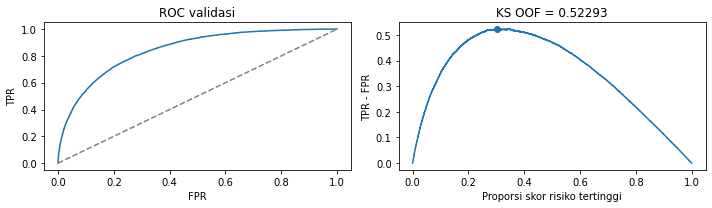

Ambang untuk memahami validasi: 0.1399
Submission tetap probabilitas kontinu; ambang ini tidak diterapkan ke CSV.


In [54]:
validation_frame = v4_oof
validation_probability = validation_frame["version4"].to_numpy()
y_valid = validation_frame.target.astype(int).to_numpy()
scores = metrics(y_valid, validation_probability)
assert (
    abs(
        scores["ks"]
        - ks_2samp(
            validation_probability[y_valid == 1], validation_probability[y_valid == 0]
        ).statistic
    )
    < 1e-12
)
display(pd.Series(scores, name="Versi 4 OOF"))
fpr, tpr, thresholds = roc_curve(y_valid, validation_probability, drop_intermediate=False)
best = np.argmax(tpr - fpr)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(fpr, tpr)
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set(title="ROC validasi", xlabel="FPR", ylabel="TPR")
fraction = y_valid.mean() * tpr + (1 - y_valid.mean()) * fpr
axes[1].plot(fraction, tpr - fpr)
axes[1].scatter([fraction[best]], [tpr[best] - fpr[best]])
axes[1].set(
    title=f"KS OOF = {scores['ks']:.5f}",
    xlabel="Proporsi skor risiko tertinggi",
    ylabel="TPR - FPR",
)
plt.tight_layout()
plt.show()
print("Ambang untuk memahami validasi:", round(float(thresholds[best]), 4))
print("Submission tetap probabilitas kontinu; ambang ini tidak diterapkan ke CSV.")

## Terakhir: hasilkan submission.csv

Kolom yang diminta adalah application_id dan default_probability. Merge satu-ke-satu memastikan urutan sample, lalu pemeriksaan membaca ulang CSV yang sudah ditulis. File historis/root tidak ditimpa. Bandingkan probabilitas dan SHA dengan checkpoint untuk memeriksa reproduksi. Selisih pembulatan kecil dapat muncul jika versi paket atau urutan penjumlahan berbeda.

In [55]:
# test_probability berada dalam urutan frame fitur, sehingga harus di-join ke sample.
predictions = pd.DataFrame(
    {
        "application_id": test_data.application_id.to_numpy(),
        "default_probability": np.asarray(test_probability),
    }
)
assert predictions.application_id.is_unique
assert set(predictions.application_id) == set(sample.application_id)
submission = sample[["application_id"]].merge(
    predictions, on="application_id", how="left", validate="one_to_one", sort=False
)
assert submission.shape == (len(sample), 2)
assert submission.application_id.equals(sample.application_id)
assert submission.columns.tolist() == ["application_id", "default_probability"]
assert np.isfinite(submission.default_probability).all()
assert submission.default_probability.between(0, 1).all()
destination = OUT / "submission.csv"
submission.to_csv(destination, index=False, float_format="%.12f")
reloaded = pd.read_csv(destination)
assert reloaded.application_id.equals(sample.application_id)
assert reloaded.columns.tolist() == sample.columns.tolist()
assert reloaded.default_probability.notna().all()
assert reloaded.default_probability.between(0, 1).all()
result = {
    "file": str(destination.relative_to(ROOT)),
    "rows": len(reloaded),
    "sha256": hashlib.sha256(destination.read_bytes()).hexdigest(),
    "historical_file": CANONICAL_FILE,
    "historical_public_score": PUBLIC_SCORE,
}
historical = ROOT / CANONICAL_FILE
if historical.exists():
    checkpoint = pd.read_csv(historical)
    assert checkpoint.application_id.equals(reloaded.application_id)
    result["maximum_probability_difference"] = float(
        np.max(
            np.abs(
                checkpoint.default_probability.to_numpy()
                - reloaded.default_probability.to_numpy()
            )
        )
    )
    result["matches_historical_predictions_1e9"] = (
        result["maximum_probability_difference"] < 1e-9
    )
    result["exact_sha256_match"] = (
        result["sha256"] == hashlib.sha256(historical.read_bytes()).hexdigest()
    )
(OUT / "verification.json").write_text(json.dumps(result, indent=2))
display(pd.Series(result, name="Pemeriksaan submission"))
display(reloaded.default_probability.describe().to_frame("probabilitas"))
print("CSV siap:", destination)

file                                       artifacts/notebook_runs/05_v4/submission.csv
rows                                                                              30000
sha256                                890e05a3f0b09500142395d5498e939928328b2770c509...
historical_file                                                       submission_v4.csv
historical_public_score                                                            None
maximum_probability_difference                                                      0.0
matches_historical_predictions_1e9                                                 True
exact_sha256_match                                                                 True
Name: Pemeriksaan submission, dtype: object

,probabilitas
count,30000.000000
mean,0.131393
std,0.160396
min,0.000849
25%,0.023662
50%,0.064729
75%,0.175307
max,0.928239


CSV siap: /home/taqiyudinmiftah/Logika/artifacts/notebook_runs/05_v4/submission.csv


## Pertanyaan untuk review kode

    1. Apakah semua riwayat diketahui sebelum keputusan aplikasi?
    2. Apakah ada ID, target, atau informasi setelah keputusan yang masuk ke fitur?
    3. Apakah encoder dan model dilatih hanya pada baris training setiap fold?
    4. Apakah pilihan jumlah pohon/bobot memakai validasi yang juga dilaporkan?
    5. Apakah probabilitas test dirata-ratakan dengan bobot yang benar?
    6. Apakah CSV mengikuti header dan urutan sample, tanpa index tambahan?

    Public score bukan KS validasi lokal. Saat Anda mengubah parameter, skor historis
    tidak otomatis menjadi skor model baru. Gunakan CSV dari sel terakhir untuk mencoba hasilnya.